# Predicción de la carga de primera falla en estructuras pantográficas

Melissa Dessire Aylas Barranca · Universidad Nacional de Ingeniería · Maestría en Inteligencia Artificial  
Trabajo de Investigación II · Docente: Glen Dario Rodríguez Rafael

## 0. Comparación preliminar de la carga de primera falla

### 0.1 Baselines preliminares

La referencia principal predice la carga media del entrenamiento para el mismo nivel celular Y. La mediana global y la regresión Ridge del estudio anterior sirven de referencias adicionales. En las tablas, el error absoluto medio (MAE) y la raíz del error cuadrático medio (RMSE) se expresan en newtons. Un valor menor indica mayor precisión.

In [1]:
from pathlib import Path
import sys

carpeta_cuaderno = Path.cwd()
if not (carpeta_cuaderno / "presentacion.py").is_file() and (carpeta_cuaderno / "notebooks/presentacion.py").is_file():
    carpeta_cuaderno = carpeta_cuaderno / "notebooks"
    sys.path.insert(0, str(carpeta_cuaderno))

import presentacion as vista
from presentacion import MODELOS, PROTOCOLOS

panel_baselines = vista.panel()

| Referencia | MAE [N] | RMSE [N] | R² | MAE nivel Y [N] |
| :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | 10,126 | 12,308 | 0,956 | 80,593 |
| Ridge histórico | 13,247 | 16,346 | 0,923 | 57,637 |
| Mediana de entrenamiento | 49,748 | 64,699 | -0,213 | 97,511 |

### 0.2 Modelos de regresión con parámetros iniciales

Cada modelo predice la misma carga a partir de la geometría previa al ensayo. MAE, RMSE y R² corresponden a configuraciones reservadas. La última columna muestra el MAE al retirar un nivel Y completo.

In [2]:
portada_resultados = vista.panel()

| Modelo | MAE [N] | RMSE [N] | R² | MAE nivel Y [N] |
| :--- | ---: | ---: | ---: | ---: |
| Lineal múltiple | 9,664 | 12,308 | 0,956 | 40,915 |
| Árbol de decisión | 10,956 | 14,892 | 0,936 | 61,289 |
| XGBoost | 11,754 | 15,093 | 0,934 | 60,684 |
| CatBoost | 12,148 | 15,596 | 0,930 | 74,726 |
| K vecinos | 12,429 | 14,923 | 0,935 | 64,849 |
| SVR con núcleo RBF | 15,651 | 19,096 | 0,894 | 82,358 |

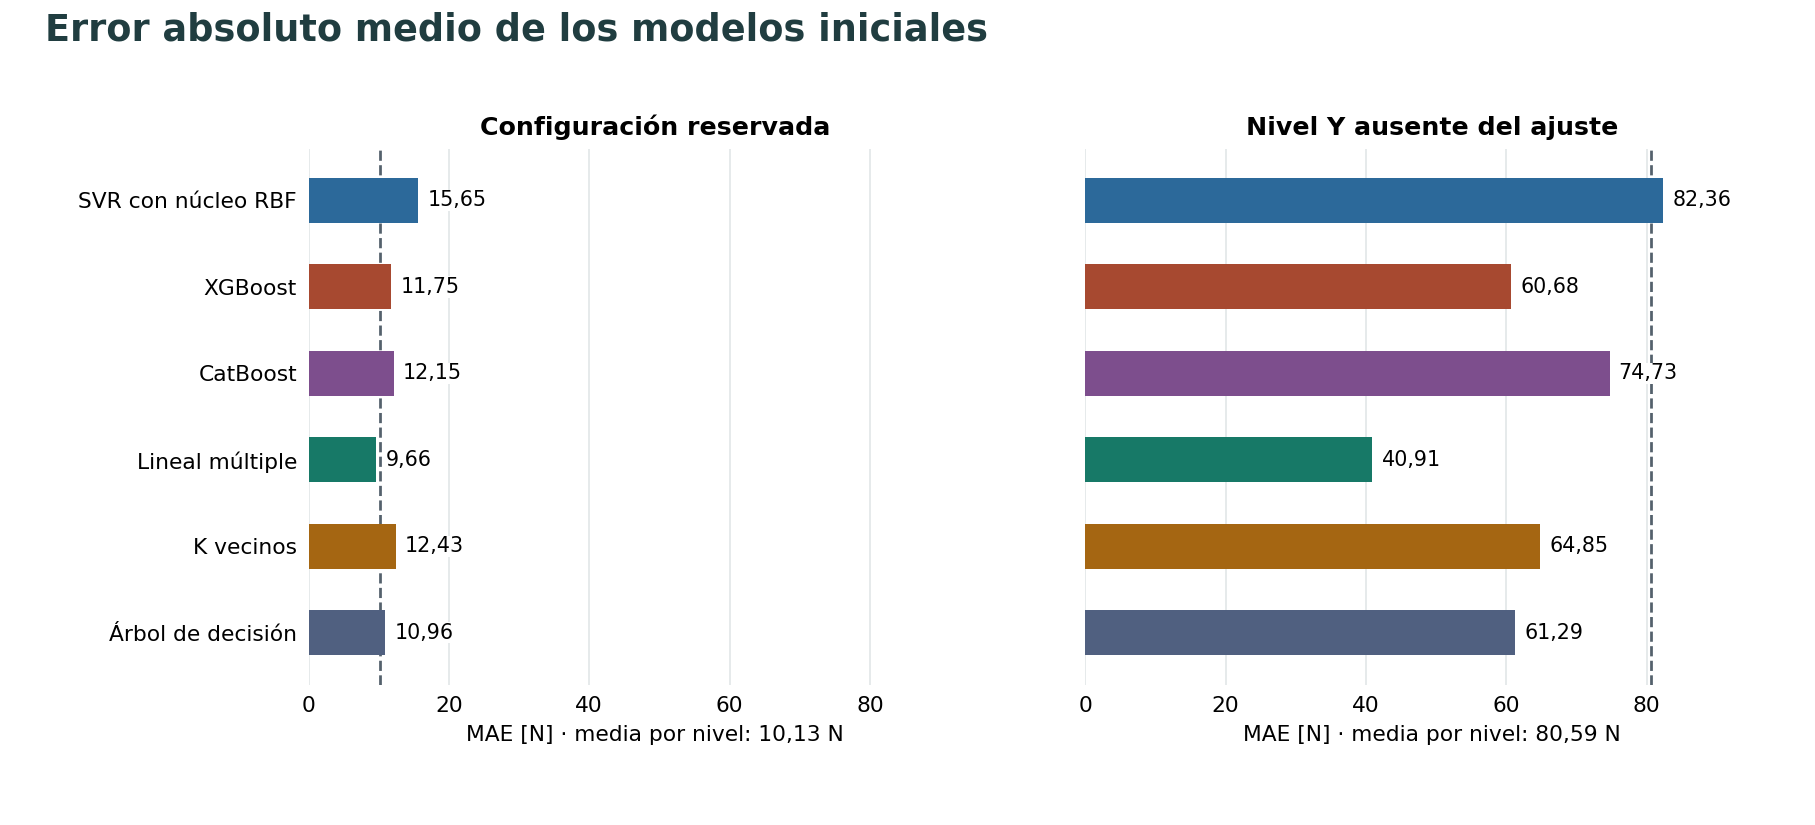

In [3]:
panel_mae = vista.panel()

Cada barra promedia las diferencias absolutas entre la carga predicha y la medida, en newtons. La línea discontinua marca el MAE de la media por nivel. En el panel derecho, el nivel Y está ausente y la referencia usa la media global del entrenamiento. Una barra más corta que esa referencia indica menor error.

In [4]:
panel_interpretacion_1 = vista.panel()

  Interpretación. En configuraciones reservadas, Lineal múltiple registra el menor    
  MAE (9,664 N), frente a 10,126 N de la media por nivel. Para el mismo regresor, el  
  error sube a 40,915 N al retirar un nivel completo.                                 

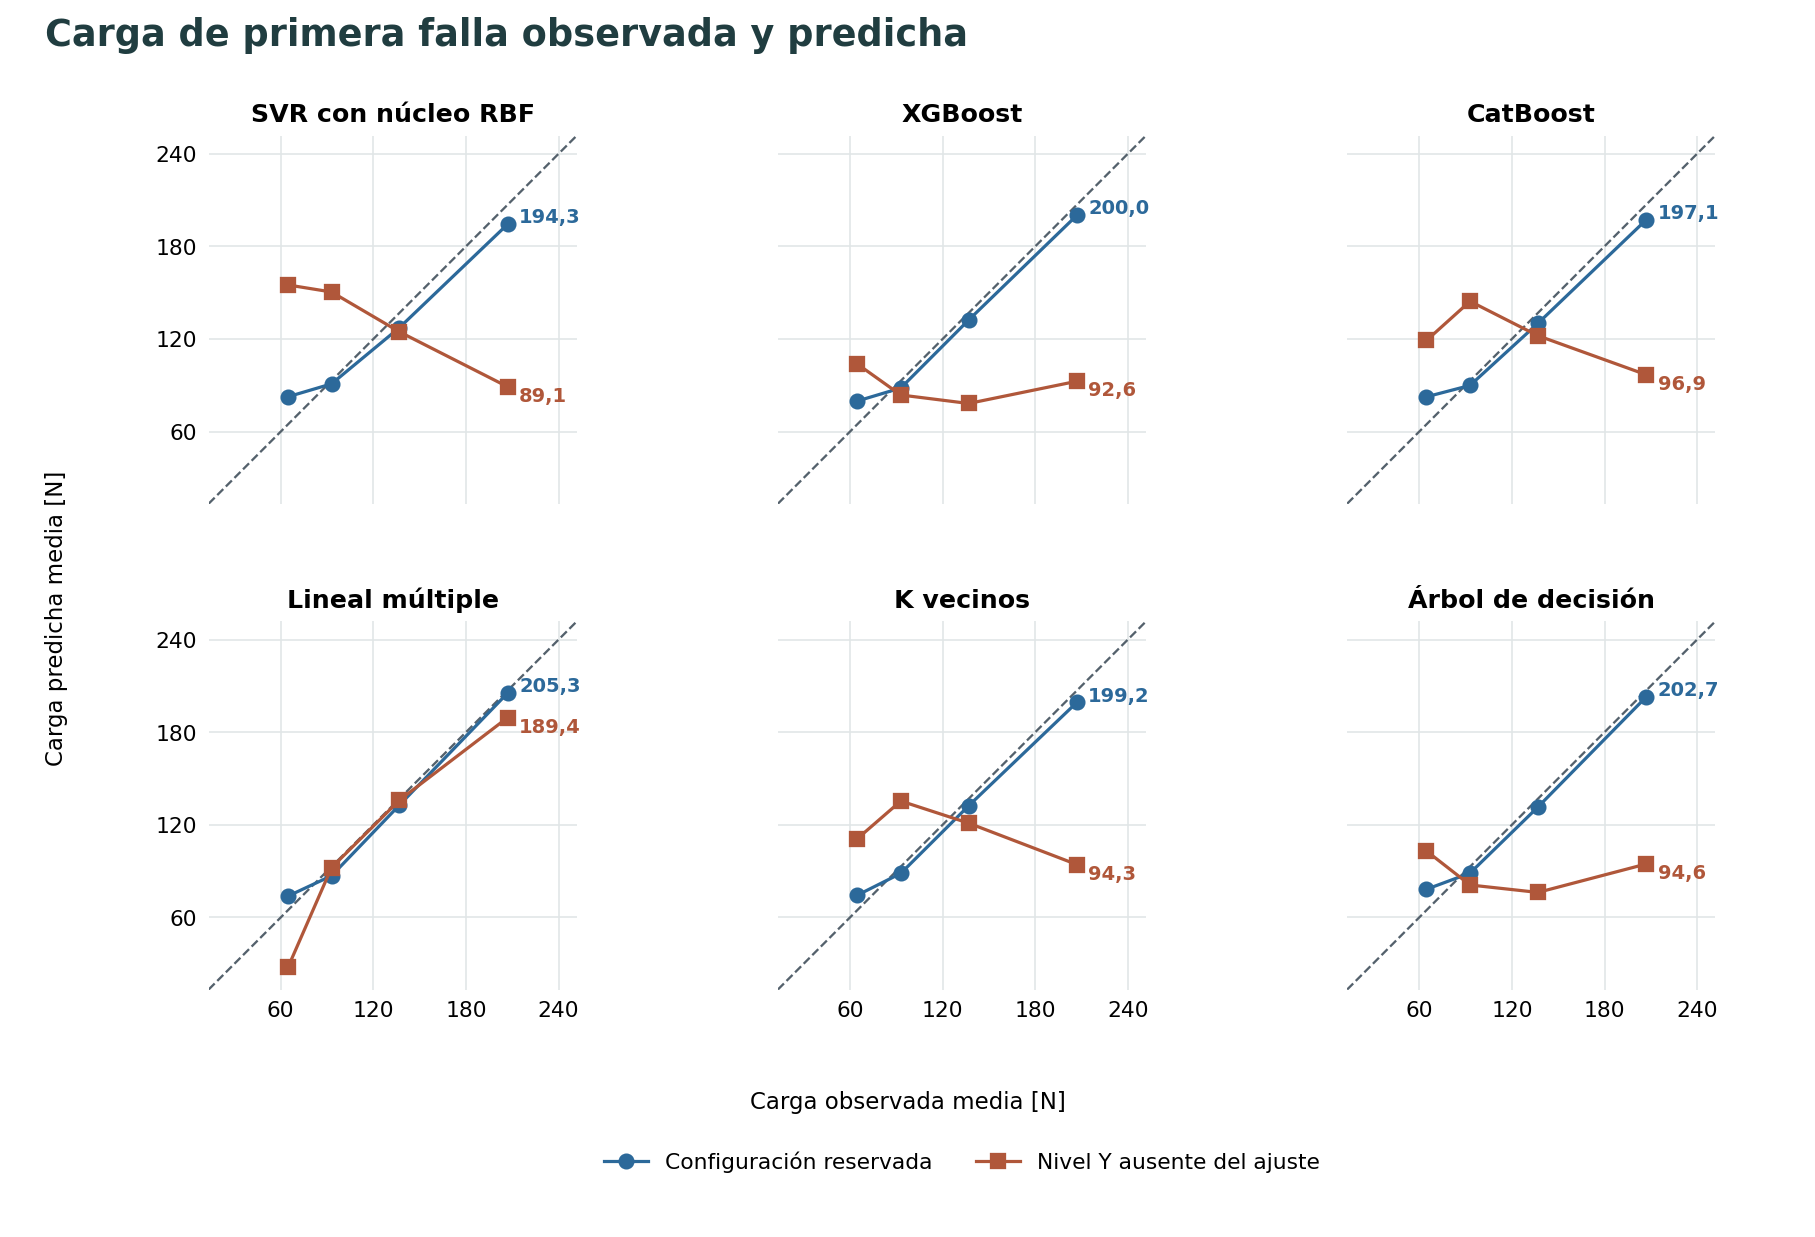

In [5]:
panel_carga = vista.panel()

Cada marca representa las medias de carga observada y predicha en un cuartil de carga observada. Una curva por debajo de la diagonal indica subestimación en ese tramo. La diferencia vertical con signo (predicción menos medición) es el sesgo medio del tramo.

In [6]:
panel_interpretacion_2 = vista.panel()

  Interpretación. En el cuartil de mayor carga, la media observada es 206,89 N. La    
  regresión lineal predice 205,27 N con niveles conocidos y 189,37 N al retirar un    
  nivel. La subestimación media de la carga alta aumenta al retirar el nivel.         

### 0.3 Ajuste de hiperparámetros y error en las mismas probetas

Cada pareja de columnas compara la misma familia con sus parámetros iniciales y con los elegidos por búsqueda aleatoria en la validación interna. El apartado 5 detalla cómo se eligieron.

In [7]:
panel_comparaciones = vista.panel()

| Procedimiento | Config. inicial [N] | Config. ajustada [N] | Nivel Y inicial [N] | Nivel Y ajustada [N] |
| :--- | ---: | ---: | ---: | ---: |
| Primera del cribado | 11,095 | 11,263 | 82,358 | 81,106 |
| Segunda del cribado | 13,356 | 13,749 | 76,193 | 73,887 |
| Selector interno | 12,365 | 12,998 | 82,358 | 81,106 |

## 1. Datos experimentales y diseño de la validación

### 1.1 Carga medida en la primera falla

La variable `First_Failure_Load_N` recoge la fuerza registrada en la primera rotura de fibra o pivote. Cada fila de la tabla curada `model_table.csv` corresponde a una probeta con esa carga observada. El cuaderno recupera la geometría admisible de `features.csv` y los grupos de entrenamiento y prueba de `particiones_externas.csv`. Las copias versionadas de estas entradas están incluidas en el cuaderno.

In [8]:
from __future__ import annotations

import hashlib
import json

import numpy as np
import pandas as pd

import graficas

In [9]:
# Insumos previos al benchmark: casos medidos, definiciones y antecedentes.
from io import StringIO
from pathlib import Path
from urllib.request import urlopen

REVISION_DATOS = "ed6cd3385bf3e282535804c61d341e008627ab16"
URL_DATOS = f"https://raw.githubusercontent.com/melissaaylasb-sudo/T02_MIA14_SeccionB/{REVISION_DATOS}/"
ARCHIVOS = {
    "muestras": "data/processed/preliminary/model_table.csv",
    "features": "docs/benchmark/features.csv",
    "particiones": "reports/permutation_importance/tables/particiones_externas.csv",
    "historia": "docs/benchmark/antecedentes_metricas.csv",
    "previo": "reports/permutation_importance/tables/metricas_resumen.csv",
    "decisiones_fe": "reports/feature_engineering/tables/decisiones.csv",
    "experimento": "config/benchmark_regresion.json",
    "politica": "config/lectura_benchmark_regresion.json",
}

In [10]:
# Prioridad: checkout completo, copia adjunta al notebook y revisión fija en GitHub.
RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / ARCHIVOS["experimento"]).is_file()), None)

def fuentes_del_notebook() -> dict:
    """Encuentra la copia en el .ipynb original o en el único .ipynb de la carpeta."""
    original = carpeta_cuaderno / "Comparativa_6_Modelos_Regresion_Pantograficas.ipynb"
    candidatos = [original] if original.is_file() else list(carpeta_cuaderno.glob("*.ipynb"))
    if len(candidatos) == 1:
        archivo = json.loads(candidatos[0].read_text(encoding="utf-8-sig"))
        return archivo.get("metadata", {}).get("fuentes_benchmark", {})
    return {}

copia = fuentes_del_notebook() if RAIZ is None else {}
if copia and copia.get("revision") != REVISION_DATOS:
    raise ValueError("La revisión de la copia adjunta al notebook difiere del protocolo.")
ORIGEN_INSUMOS = "checkout local" if RAIZ is not None else (
    "copia del notebook" if copia else "GitHub (revisión fijada)"
)

In [11]:
# Comprueba la identidad de las fuentes antes de preparar los datos.
def texto_fuente(ruta: str) -> str:
    """Lee UTF-8 y normaliza los saltos de línea para comparar Windows y Linux."""
    try:
        if RAIZ is not None:
            contenido = (RAIZ / ruta).read_bytes()
        elif copia:
            return copia["archivos_utf8"][ruta]
        else:
            with urlopen(URL_DATOS + ruta, timeout=20) as respuesta:
                contenido = respuesta.read()
    except (OSError, KeyError) as exc:
        raise RuntimeError(
            f"No se pudo leer {ruta} desde {ORIGEN_INSUMOS}. Usa el notebook publicado "
            "completo, su checkout o una conexión a GitHub."
        ) from exc
    return contenido.decode("utf-8-sig").replace("\r\n", "\n")

entradas = {k: texto_fuente(ruta) for k, ruta in ARCHIVOS.items()}
huellas_entradas = {k: hashlib.sha256(t.encode()).hexdigest() for k, t in entradas.items()}
manifiesto = "\n".join(sorted(f"{ARCHIVOS[k]} {sha}" for k, sha in huellas_entradas.items()))
if hashlib.sha256(manifiesto.encode()).hexdigest() != "3accfa5425f81dba2e22a556dbf6b1843b658af4743c825c4b068f6b27f07ca7":
    raise ValueError(f"Algún insumo difiere de la revisión {REVISION_DATOS[:7]}. "
                     "Revisa los cambios locales antes de comparar métricas.")

In [12]:
def tabla_fuente(nombre: str) -> pd.DataFrame:
    """Conserva la precisión de las mediciones y de los controles históricos."""
    return pd.read_csv(StringIO(entradas[nombre]), float_precision="round_trip")

muestras = tabla_fuente("muestras")
features = tabla_fuente("features")
particiones = tabla_fuente("particiones")
historia = tabla_fuente("historia")
previo = tabla_fuente("previo")
decisiones_fe = tabla_fuente("decisiones_fe")

CFG = json.loads(entradas["experimento"])
LECTURA = json.loads(entradas["politica"])
target = CFG["target"]
grupo_cols = ["n_cells_Y", "Fiber_height", "Pivot_height"]
GEOMETRY = features["Feature"].tolist()

### 1.2 Geometría admisible antes del ensayo

La representación A utiliza dimensiones y conteos de fibras, pivotes y celdas. Se excluyen el identificador, la carga terminal, las energías y los desplazamientos registrados durante el ensayo. Cada variable conserva la unidad documentada en la fuente.

In [13]:
predictores = features["Feature"].tolist()
assert target == "First_Failure_Load_N" and CFG["unidad"] == "N"
assert len(predictores) == len(set(predictores)) and set(predictores).issubset(muestras)
assert not set(predictores).intersection({target, "Case_n", "__source_record", "Ultimate_Load", "Maximum_Displacement"})
assert muestras.Case_n.is_unique and muestras[target].notna().all()

In [14]:
vista.mostrar_geometria(features, decisiones_fe)

| Variable | Unidad | Medida geométrica |
| :--- | :--- | :--- |
| n_cells_Y | conteo | Número de celdas en la dirección Y; indicador de la arquitectura. |
| Fiber_height | mm | Altura de la sección de las fibras. |
| Fiber_base | mm | Ancho de sección; algunas fuentes geométricas discrepan. |
| Fiber_total_length | mm | Longitud declarada del conjunto de fibras, vinculada al nivel Y. |
| Fiber_total_volume | mm³ | Volumen declarado de fibras; relacionado con el de pivotes. |
| Pivot_height | mm | Altura nominal de los elementos de unión. |
| Pivot_radius | mm | Radio nominal del pivote; constante en la campaña. |
| Pivot_total_number | conteo | Cantidad de conexiones; depende de la arquitectura observada. |
| Pivot_total_volume | mm³ | Volumen declarado del conjunto de uniones. |
| Sample_total_volume | mm³ | Volumen declarado del espécimen según CAD; no se sustituye por una suma. |

**Variantes geométricas B–D y motivo para conservar A**

| experimento | referencia | intervencion | delta_MAE_N | decision |
| :--- | :--- | :--- | ---: | :--- |
| B | A | Añadir dos segundos momentos de área de la sección de fibra | -0,412 | Mantener en evaluación |
| C | B | Añadir ln(volumen_pivotes / volumen_fibras) | 0,079 | Descartar |
| D | C | Retirar longitud total de fibras, número de pivotes y volumen de fibras del bloque original | 4,121 | Descartar |

### 1.3 Grupos reservados para evaluar la predicción

| Protocolo | Grupo que se aparta antes de ajustar el modelo | Qué se evalúa |
|---|---|---|
| Configuración nominal | Probetas con la misma combinación de celdas en Y, altura de fibra y altura de pivote. | Predecir otra combinación geométrica con niveles Y ya observados. |
| Nivel celular Y | Todas las probetas con el mismo número de celdas en Y. | Predecir un nivel ausente del entrenamiento. Retirar un nivel intermedio prueba interpolación en Y y retirar un extremo prueba extrapolación en Y. |

Las probetas con la misma clave nominal permanecen juntas. La campaña no documenta si constituyen réplicas de fabricación.

In [15]:
for _, fila in particiones.iterrows():
    train, test = [set(map(int,str(fila[k]).split(";"))) for k in ("casos_train","casos_test")]
    assert not train & test and train | test == set(muestras.Case_n)

## 2. Modelos de referencia preliminares

Los baselines establecen cuánto error puede reducir un modelo al incorporar más información geométrica. Se recalculan con los mismos grupos de entrenamiento y prueba que los seis regresores iniciales.

### 2.1 Referencias del estudio anterior

Las tablas siguientes identifican los modelos y las métricas registrados en las etapas previas del proyecto. La comparación del presente cuaderno utiliza las predicciones recalculadas bajo protocolos comunes.

In [16]:
vista.mostrar_antecedentes(previo, historia)

**Métricas del estudio anterior**

| protocolo | modelo | MAE_N | RMSE_N | R2 |
| :--- | :--- | ---: | ---: | ---: |
| configuracion | Ridge | 13,247 | 16,346 | 0,923 |
| configuracion | SVR_RBF | 15,651 | 19,096 | 0,894 |
| configuracion | Media_por_nivel | 10,126 | 12,308 | 0,956 |
| familia | Ridge | 57,637 | 60,428 | -0,058 |
| familia | SVR_RBF | 82,358 | 88,039 | -1,246 |
| familia | Media_por_nivel | 80,593 | 87,521 | -1,219 |

**Modelos evaluados por etapa previa**

| etapa | Modelos evaluados |
| :--- | :--- |
| 04 · variantes | Media de entrenamiento, Ridge(alpha=1, solver=svd) |
| 04 · familias fijas | Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess |
| 05 · ajuste anidado | Baseline_Ridge, Ridge, ElasticNet, SVR_RBF, RandomForest, ExtraTrees, GaussianProcess, GradientBoosting, Selector_interno |
| 06 · importancia anterior | Dummy, Ridge, ElasticNet |
| 06 · permutación | Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess, Mediana, Media_por_nivel |

### 2.2 Reglas de predicción de los baselines

| Referencia | Predicción para una probeta reservada |
|---|---|
| Media por nivel Y | Promedio de las cargas de entrenamiento con su mismo valor de `n_cells_Y`. Cuando ese nivel queda completamente reservado, se usa la media global del entrenamiento. |
| Mediana de entrenamiento | Mediana de las cargas de entrenamiento, idéntica para cualquier geometría de prueba del mismo pliegue. |
| Ridge histórico | Combinación lineal de las variables geométricas con penalización cuadrática de los coeficientes. La imputación y la estandarización se ajustan dentro del entrenamiento. |

In [17]:
from time import perf_counter
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits


class MeanByLevel(RegressorMixin, BaseEstimator):
    """Media Y de train; si falta el nivel usa la media global del mismo train."""

    def fit(self, X: pd.DataFrame, y: np.ndarray):
        self.global_mean_ = float(np.mean(y))
        self.means_ = pd.Series(np.asarray(y)).groupby(X.n_cells_Y.to_numpy()).mean().to_dict()
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        check_is_fitted(self, 'means_')
        return X.n_cells_Y.map(self.means_).fillna(self.global_mean_).to_numpy(float)

In [18]:
def referencia_inicial(familia):
    parametros = CFG["parametros_iniciales"][familia]
    if familia == "Dummy_mediana":
        return Pipeline([("model", DummyRegressor(**parametros))])
    if familia == "Media_por_nivel":
        return Pipeline([("model", MeanByLevel())])
    if familia != "Ridge_historico":
        raise ValueError(f"Referencia inesperada: {familia}")
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("variance", VarianceThreshold()),
        ("scale", StandardScaler()),
        ("model", Ridge(**parametros)),
    ])

def casos_de(texto):
    return [int(caso) for caso in str(texto).split(";")]

In [19]:
casos = muestras.set_index("Case_n").sort_index()
X_base, y_base = casos[predictores], casos[target]
ajustes_base, predicciones_base = {}, []
with threadpool_limits(limits=1):
    for reserva in particiones.itertuples():
        train, test = casos_de(reserva.casos_train), casos_de(reserva.casos_test)
        assert set(train).isdisjoint(test)
        for familia in CFG["referencias"]:
            modelo = referencia_inicial(familia)
            inicio = perf_counter()
            modelo.fit(X_base.loc[train], y_base.loc[train])
            t_fit = perf_counter() - inicio
            inicio = perf_counter()
            pred = modelo.predict(X_base.loc[test])
            t_pred = perf_counter() - inicio
            clave = (reserva.protocolo, reserva.fold, familia)
            ajustes_base[clave] = (modelo, t_fit, pred, t_pred, modelo.predict(X_base.loc[train]))
            for caso, valor_predicho in zip(test, pred):
                predicciones_base.append((reserva.protocolo, familia, caso, y_base.at[caso], valor_predicho))

### 2.3 Error de referencia en los grupos reservados

Se compara la carga medida de cada probeta reservada con su predicción. El promedio de estas diferencias absolutas se calcula por separado para cada baseline y protocolo. La sección 4.2 desarrolla el cálculo con valores de la campaña.

In [20]:
base_oof = pd.DataFrame(predicciones_base, columns=["protocolo", "referencia", "caso", "observado_N", "predicho_N"])
base_oof["error_absoluto_N"] = (base_oof.predicho_N - base_oof.observado_N).abs()
assert not base_oof.duplicated(["protocolo", "referencia", "caso"]).any()
resumen_base = base_oof.groupby(["protocolo", "referencia"]).agg(
    casos=("caso", "size"), MAE_N=("error_absoluto_N", "mean")
)
assert resumen_base.casos.eq(len(casos)).all()
vista.mostrar_baselines(resumen_base)

| Referencia | Configuración · MAE [N] | Nivel Y · MAE [N] |
| :--- | ---: | ---: |
| Mediana de entrenamiento | 49,748 | 97,511 |
| Media por nivel Y | 10,126 | 80,593 |
| Ridge histórico | 13,247 | 57,637 |

Con el nivel Y presente en entrenamiento, la media por nivel tiene un error de 10,13 N. Al reservar el nivel completo, la media de entrenamiento da 80,59 N.

## 3. Modelos de regresión y preparación de la geometría

### 3.1 Fundamento de los seis modelos preliminares

Todos estiman la carga de primera falla en newtons a partir de la misma geometría y con las mismas particiones. La elección cubre relaciones lineales, semejanza local, umbrales e interacciones. Un antecedente próximo es el estudio de Huang y colaboradores, que evaluó SVR, XGBoost y CatBoost en retículas impresas usando parámetros de fabricación. Aquí se estudian medidas geométricas antes del ensayo. [Huang et al., retículas impresas](https://link.springer.com/article/10.1007/s40964-025-01409-6)

| Modelo | Cómo obtiene la carga | Justificación metodológica |
|---|---|---|
| Regresión lineal múltiple | Suma un intercepto y las medidas geométricas multiplicadas por sus coeficientes. Ajusta estos coeficientes minimizando la suma de errores cuadrados. | Cuantifica cuánto se puede predecir con una relación lineal aditiva y ofrece una ecuación en unidades físicas. [Mínimos cuadrados](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) |
| K vecinos | Regresión local. Busca geometrías cercanas y promedia sus cargas medidas. | Permite evaluar si la semejanza geométrica basta para predecir la carga sin imponer una pendiente común. |
| SVR con núcleo RBF | Combina similitudes con las geometrías de soporte mediante un núcleo radial. Penaliza los errores que exceden una banda de tolerancia ε. | Representa una relación no lineal que cambia suavemente con la geometría. [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) |
| Árbol de decisión | Divide el espacio geométrico por umbrales para reducir el error cuadrático. Predice la media de las cargas que llegaron a la hoja. | Permite comprobar si unas pocas reglas sobre dimensiones geométricas bastan para distinguir intervalos de carga. [Árboles de regresión](https://scikit-learn.org/stable/modules/tree.html#regression) |
| XGBoost | Suma árboles de regresión sucesivos. Cada árbol corrige parte del error del conjunto anterior. La profundidad y la penalización de las hojas limitan su complejidad. | Admite interacciones, como que el efecto predictivo de una altura cambie según el nivel Y. [Árboles con boosting](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) |
| CatBoost | Suma árboles simétricos. Dentro de cada árbol aplica la misma regla de corte a todas las ramas de una profundidad dada. | Examina si una estructura de cortes más restringida captura interacciones entre estas medidas numéricas. [Construcción de los árboles](https://catboost.ai/docs/en/references/training-parameters/common#grow_policy) |

También se han estudiado modelos de regresión para la templabilidad de aceros y la resistencia a cortante de vigas. La elección del modelo para estas estructuras pantográficas depende de sus propios errores de validación. [Nenchev et al., templabilidad](https://doi.org/10.1007/s12613-022-2437-0) · [Megahed, resistencia a cortante](https://www.nature.com/articles/s41598-024-64386-w)

### 3.2 Regresión local por vecinos geométricos

La carga es continua. Por eso se emplea `KNeighborsRegressor`, que devuelve un valor en newtons. La configuración inicial busca los **tres vecinos más próximos** por distancia euclídea en la geometría estandarizada y asigna a cada carga el mismo peso. Si sus cargas medidas son $F_1$, $F_2$ y $F_3$, la predicción es $(F_1+F_2+F_3)/3$. Cada vecino procede del entrenamiento de esa partición. [Regresión por vecinos en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)

Su inclusión responde a la hipótesis de que geometrías próximas podrían fallar bajo cargas parecidas. Al retirar un nivel Y, los vecinos tienen que proceder de otros niveles. La predicción queda entre las cargas de los vecinos elegidos, lo que limita su capacidad para anticipar una carga más extrema. El apartado 4.2 reconstruye una predicción de K vecinos con cargas medidas de la campaña.

In [21]:
from collections import defaultdict
from itertools import product
from typing import Any
import warnings

from sklearn.base import TransformerMixin
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, export_text
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

GEOMETRY, TARGET, GROUP_COLUMNS = predictores, target, grupo_cols
cfg = CFG
INITIAL, REFS = tuple(cfg["familias"]), tuple(cfg["referencias"])
ADAPT = ("Tuning_rango_1", "Tuning_rango_2", "Selector_tuning")
UNITS = dict(zip(features.Feature, features.Unidad))
Params = dict[str, Any]
Rows = dict[str, list[dict[str, Any]]]
assert INITIAL == MODELOS and len(GEOMETRY) == len(set(GEOMETRY)) == 10

In [22]:
def nominal_groups(frame, columns):
    if frame[columns].isna().any().any():
        raise ValueError('No se pueden verificar grupos nominales con claves ausentes.')
    return frame[columns].apply(lambda row: '|'.join((format(float(v), '.12g') for v in row)), axis=1)


frame = muestras.copy().sort_values("Case_n").reset_index(drop=True)
assert "Case_n" in frame and frame.Case_n.is_unique and not frame.Case_n.isna().any()
frame = frame.loc[frame[TARGET].notna()].reset_index(drop=True)
assert np.isfinite(frame[TARGET]).all() and (frame[TARGET] > 0).all()
X = frame.set_index("Case_n")[GEOMETRY]
y = frame.set_index("Case_n")[TARGET]
nominal = nominal_groups(frame, GROUP_COLUMNS).to_numpy()
indices = {int(case): i for i, case in enumerate(X.index)}

In [23]:
def indices_casos(values):
    if isinstance(values, str):
        values = values.split(";")
    return np.array([indices[int(case)] for case in values], dtype=int)

splits = {}
for protocol in cfg["protocolos"]:
    folds = particiones.loc[particiones.protocolo == protocol].sort_values("fold")
    assert folds.fold.tolist() == list(range(1, len(folds) + 1))
    splits[protocol] = [(indices_casos(r.casos_train), indices_casos(r.casos_test)) for r in folds.itertuples()]
    groups = nominal if protocol == "configuracion" else X.n_cells_Y.to_numpy()
    evaluated = []
    for tr, te in splits[protocol]:
        assert not set(tr) & set(te) and set(tr) | set(te) == set(range(len(X)))
        assert not set(groups[tr]) & set(groups[te]) and len(set(groups[te])) == 1
        evaluated.extend(te)
    assert sorted(evaluated) == list(range(len(X)))
assert len(splits["configuracion"]) == len(np.unique(nominal))
assert len(splits["familia"]) == X.n_cells_Y.nunique()

### 3.3 Parámetros iniciales de los regresores

Estas configuraciones se fijan antes de evaluar las reservas. El apartado 4 informa sus errores con esos parámetros. El apartado 5 usa la configuración inicial de cada familia ajustable como punto de partida de la búsqueda.

In [24]:
vista.mostrar_recetas(CFG["parametros_iniciales"])

| Modelo | Receta inicial |
| :--- | :--- |
| SVR con núcleo RBF | RBF, C=100, ε=5 N, γ=scale |
| XGBoost | 60 árboles, profundidad 2, η=0.075 |
| CatBoost | 60 iteraciones, profundidad 2, η=0.075 |
| Lineal múltiple | Mínimos cuadrados con intercepto y base de rango completo |
| K vecinos | k=3, p=2, pesos uniform |
| Árbol de decisión | Profundidad 2, hoja mínima 2 |

**Configuración completa y semillas**

| Modelo | Parámetros |
| :--- | :--- |
| SVR con núcleo RBF | {"kernel": "rbf", "C": 100.0, "epsilon": 5.0, "gamma": "scale"} |
| XGBoost | {"objective": "reg:squarederror", "n_estimators": 60, "max_depth": 2, "learning_rate": 0.075, "min_child_weight": 2, "reg_lambda": 3, "reg_alpha": 0, "subsample": 1, "colsample_bytree": 1, "tree_method": "hist", "n_jobs": 1, "random_state": 42, "verbosity": 0} |
| CatBoost | {"loss_function": "RMSE", "iterations": 60, "depth": 2, "learning_rate": 0.075, "l2_leaf_reg": 5, "random_strength": 0, "bootstrap_type": "No", "thread_count": 1, "allow_writing_files": false, "verbose": false, "random_seed": 42} |
| Lineal múltiple | {"fit_intercept": true} |
| K vecinos | {"n_neighbors": 3, "weights": "uniform", "metric": "minkowski", "p": 2, "algorithm": "brute", "n_jobs": 1} |
| Árbol de decisión | {"criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 2, "random_state": 42} |

### 3.4 Transformaciones aprendidas con el entrenamiento

El código verifica las entradas geométricas, imputa los valores ausentes con la mediana de cada variable y elimina las columnas constantes. Para la lineal, SVR y K vecinos, resta a cada variable la media de entrenamiento y divide por su desviación estándar. Así se evita que las unidades de medida, como milímetros y milímetros cúbicos, dominen el cálculo de las distancias. Los árboles usan las medidas sin estandarizar.

La regresión lineal recorre las columnas en su orden original y conserva las que aumentan el rango de la matriz centrada, con tolerancia relativa de `1e−10`. Todas las transformaciones se estiman dentro del entrenamiento correspondiente y se aplican después al grupo reservado. La respuesta permanece en newtons.

In [25]:
class GeometryContract(TransformerMixin, BaseEstimator):
    """Rechaza respuestas, identificadores, infinitos y geometrías no positivas.

    Se admiten NaN en transform para imputación con estadísticas de entrenamiento.
    Una columna completamente ausente en entrenamiento no permite estimar mediana.
    """

    def _validate(self, X):
        if not isinstance(X, pd.DataFrame) or set(X.columns) != set(GEOMETRY) or X.columns.duplicated().any():
            raise ValueError('Se requieren exclusivamente las columnas geométricas autorizadas; sin target ni identificadores.')
        x = X[GEOMETRY].apply(pd.to_numeric, errors='raise').astype(float)
        a = x.to_numpy()
        if np.isinf(a).any() or (a <= 0).any():
            raise ValueError('La geometría debe ser positiva y finita, o NaN para imputación.')
        for col in ['n_cells_Y', 'Pivot_total_number']:
            v = x[col].dropna().to_numpy()
            if not np.equal(v, np.floor(v)).all():
                raise ValueError('Los conteos geométricos deben ser enteros.')
        return x

    def fit(self, X, y=None):
        x = self._validate(X)
        if x.isna().all().any():
            raise ValueError('Una entrada carece de observaciones en entrenamiento.')
        self.feature_names_in_ = np.array(GEOMETRY, dtype=object)
        self.n_features_in_ = len(GEOMETRY)
        return self

    def transform(self, X):
        check_is_fitted(self)
        return self._validate(X)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self)
        return self.feature_names_in_.copy()

In [26]:
class FullRankBasis(TransformerMixin, BaseEstimator):
    """Base no supervisada de la matriz de diseño centrada, aprendida solo en fit."""

    def __init__(self, rtol: float=1e-10):
        self.rtol = rtol

    def fit(self, X: np.ndarray, y: np.ndarray | None=None):
        a = np.asarray(X, dtype=float)
        a = a - a.mean(axis=0)
        self.singular_values_ = np.linalg.svd(a, compute_uv=False)
        self.tol_ = float(self.rtol * self.singular_values_[0])
        selected = []
        for i in range(a.shape[1]):
            if np.linalg.matrix_rank(a[:, selected + [i]], tol=self.tol_) > len(selected):
                selected.append(i)
        if not selected:
            raise ValueError('Diseño OLS sin columnas informativas.')
        self.indices_ = np.asarray(selected, dtype=int)
        self.n_features_in_ = a.shape[1]
        self.rank_ = int(np.linalg.matrix_rank(a, tol=self.tol_))
        if self.rank_ != len(selected):
            raise ValueError('Base secuencial numéricamente ambigua; revisar la tolerancia.')
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        check_is_fitted(self, 'indices_')
        return np.asarray(X)[:, self.indices_]

In [27]:
def pipeline(family: str, params: Params, cfg: Params) -> Pipeline:
    if family in REFS:
        return referencia_inicial(family)
    constructores = {
        "SVR_RBF": SVR, "XGBoost": XGBRegressor, "CatBoost": CatBoostRegressor,
        "Lineal_multiple": LinearRegression, "KNN": KNeighborsRegressor,
        "Arbol_decision": DecisionTreeRegressor,
    }
    pasos = [
        ("contract", GeometryContract()),
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True).set_output(transform="pandas")),
        ("variance", VarianceThreshold()),
    ]
    if family in ("SVR_RBF", "KNN", "Lineal_multiple"):
        pasos.append(("scale", StandardScaler()))
    if family == "Lineal_multiple":
        pasos.append(("basis", FullRankBasis(cfg["ols"]["tolerancia_svd_relativa"])))
    return Pipeline([*pasos, ("model", constructores[family](**params))])

def feature_names(modelo):
    return np.array(GEOMETRY)[modelo.named_steps["variance"].get_support()]

## 4. Evaluación de los modelos con parámetros iniciales

### 4.1 Predicciones para grupos excluidos del entrenamiento

En cada turno se aparta un grupo completo, se ajusta el modelo con los demás grupos y se predice la carga de las probetas apartadas. Al rotar los grupos se obtiene una predicción de prueba por probeta para cada combinación de modelo y protocolo. Se conserva tanto la carga medida como la predicha para calcular los errores.

In [28]:
def _object(value: Any) -> str:
    return json.dumps(value, ensure_ascii=False, sort_keys=True, allow_nan=False,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x))


def _ids(values: Any) -> str:
    return ';'.join((str(int(v)) for v in values))


def _stage(proc: str) -> str:
    return 'inicial' if proc in INITIAL else 'referencia' if proc in REFS else 'optimizada'


def _group(proc: str) -> str:
    if proc in REFS:
        return 'referencia'
    if proc in ADAPT:
        return 'procedimiento_adaptativo'
    return 'A_materiales' if proc in INITIAL[:3] else 'B_clasicos'

In [29]:
def metrics(y: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    """Métricas en N; R² solo definido para al menos dos respuestas diferentes."""
    y = np.asarray(y, dtype=float)
    p = np.asarray(pred, dtype=float)
    if y.shape != p.shape or y.ndim != 1 or (not len(y)) or (not np.isfinite([y, p]).all()):
        raise ValueError('Respuestas/predicciones inválidas.')
    e = p - y
    a = np.abs(e)
    return {'MAE_N': float(a.mean()), 'RMSE_N': float(np.sqrt((e ** 2).mean())),
        'MedAE_N': float(np.median(a)),
        'R2_OOF': float(r2_score(y, p)) if len(y) > 1 and np.ptp(y) > 0 else np.nan, 'sesgo_N': float(e.mean())}


def _predict(obj: Any, X: pd.DataFrame) -> tuple[np.ndarray, float]:
    start = perf_counter()
    p = np.asarray(obj.predict(X), dtype=float).reshape(-1)
    seconds = perf_counter() - start
    if len(p) != len(X) or not np.isfinite(p).all():
        raise ValueError('Predicción no finita o de longitud incorrecta.')
    return (p, seconds)

In [30]:
def guardar_ajuste(family, params, X, context, rows, obj, seconds, avisos=""):
    record = {**context, 'familia_real': family, 'n_train': len(X), 'casos_train': _ids(X.index),
        'parametros_json': _object(params), 'tiempo_ajuste_s': seconds,
        'avisos': avisos}
    for step, field in [('imputer', 'statistics_'), ('scale', 'mean_'), ('scale', 'scale_')]:
        if step in obj.named_steps:
            record[step + field] = _object(getattr(obj.named_steps[step], field).tolist())
    rows['ajustes'].append(record)


def _fit(family: str, params: Params, cfg: Params, X: pd.DataFrame, y: pd.Series, context: Params,
    rows: Rows) -> tuple[Any, float]:
    if not X.index.equals(y.index) or not X.index.is_unique or set(X) != set(GEOMETRY):
        raise ValueError('Contrato de entrenamiento inválido.')
    if family == 'KNN' and params['n_neighbors'] > len(y):
        raise ValueError('k supera el train del pliegue.')
    obj = pipeline(family, params, cfg)
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        obj.fit(X, y)
    seconds = perf_counter() - start
    guardar_ajuste(family, params, X, context, rows, obj, seconds,
                   ' | '.join(sorted({str(w.message) for w in caught})))
    return obj, seconds


def evaluar_reserva(familia, parametros, X_train, y_train, X_test, contexto, cfg, rows):
    """Ajustar en entrenamiento y cronometrar la predicción de la reserva por separado."""
    modelo, t_ajuste = _fit(familia, parametros, cfg, X_train, y_train, contexto, rows)
    pred_test, t_pred = _predict(modelo, X_test)
    pred_train, _ = _predict(modelo, X_train)
    return modelo, t_ajuste, pred_test, t_pred, pred_train

In [31]:
def _record(proc: str, family: str, stage_ctx: Params, X: pd.DataFrame, y: pd.Series, train: np.ndarray,
    test: np.ndarray, nominal: np.ndarray, p: np.ndarray, pt: np.ndarray, fit_s: float, predict_s: float,
    search_s: float, initial: np.ndarray, rows: Rows) -> None:
    ctx = {**stage_ctx, 'procedimiento': proc, 'etapa': _stage(proc), 'familia_real': family}
    yt = y.iloc[test].to_numpy()
    met = metrics(yt, p)
    rows['metricas_folds'].append({**ctx, 'n_train': len(train), 'n_test': len(test),
        'MAE_train_N': float(np.mean(np.abs(y.iloc[train].to_numpy() - pt))), 'MAE_validacion_N': met['MAE_N'],
        'RMSE_validacion_N': met['RMSE_N'], 'MedAE_validacion_N': met['MedAE_N'],
        'sesgo_validacion_N': met['sesgo_N'], 'tiempo_ajuste_s': fit_s, 'tiempo_prediccion_s': predict_s,
        'tiempo_busqueda_s': search_s})
    for j, obs, pred, orig in zip(test, yt, p, initial):
        rows['predicciones_oof'].append({**ctx, 'Case_n': int(X.index[j]),
            'n_cells_Y': int(X.iloc[j].n_cells_Y), 'grupo_nominal': nominal[j], 'observado_N': obs,
            'predicho_N': pred, 'residuo_N': obs - pred, 'error_absoluto_N': abs(obs - pred),
            'predicho_inicial_misma_familia_N': orig})
    for j, pred in zip(train, pt):
        rows['predicciones_train'].append({**ctx, 'Case_n': int(X.index[j]), 'observado_N': y.iloc[j],
            'predicho_N': pred})

In [32]:
def ecuacion_en_unidades_originales(estimador):
    """Deshace el escalado de la base OLS y conserva las unidades geométricas."""
    indice = estimador.named_steps["basis"].indices_
    escala = estimador.named_steps["scale"]
    modelo = estimador.named_steps["model"]
    coeficientes = pd.Series(modelo.coef_ / escala.scale_[indice],
                             index=feature_names(estimador)[indice])
    intercepto = float(modelo.intercept_ - coeficientes.to_numpy() @ escala.mean_[indice])
    return intercepto, coeficientes

In [33]:
def _diagnose(obj: Any, family: str, X: pd.DataFrame, Xt: pd.DataFrame, ctx: Params, rows: Rows) -> None:
    """Diagnósticos descriptivos del modelo ajustado; nunca intervienen en el cribado."""
    m = obj.named_steps['model']
    rec = {**ctx, 'familia_real': family, 'n_train': len(X)}
    if 'variance' in obj.named_steps:
        names = list(feature_names(obj))
        rec['n_features_tras_varianza'] = len(names)
    if family == 'Lineal_multiple':
        basis = obj.named_steps['basis']
        sing = basis.singular_values_
        z = obj[:-2].transform(X)
        zb = basis.transform(z)
        s = np.linalg.svd(zb - zb.mean(axis=0), compute_uv=False)
        intercept, pendientes = ecuacion_en_unidades_originales(obj)
        keep, phys = pendientes.index.to_list(), pendientes.to_numpy()
        rec.update(rango_centrado=basis.rank_, rango_base=len(keep),
            condicion_centrada=float('inf') if basis.rank_ < len(names) else sing[0] / sing[-1],
            condicion_base=s[0] / s[-1], variables_base=';'.join(keep), intercepto_fisico_N=intercept,
            tol_svd=basis.tol_, singulares_centrados_json=_object(sing.tolist()))
        for c in GEOMETRY:
            i = keep.index(c) if c in keep else None
            rows['coeficientes_ols'].append({**ctx, 'variable': c, 'unidad_variable': UNITS[c],
                'estado': 'retenida' if i is not None else 'redundante_en_train' if c in names else 'constante_en_train', 'coeficiente_N_por_unidad': phys[i] if i is not None else np.nan, 'coeficiente_estandarizado_N': m.coef_[i] if i is not None else np.nan, 'intercepto_fisico_N': intercept})
        np.testing.assert_allclose(intercept + obj[:2].transform(X)[keep].to_numpy() @ phys, obj.predict(X), atol=1e-07, rtol=1e-10)
    elif family == 'SVR_RBF':
        rec.update(n_vectores_soporte=len(m.support_), fraccion_vectores_soporte=len(m.support_) / len(X),
            casos_soporte=_ids(X.index[m.support_]))
    elif family == 'KNN':
        dist, idx = m.kneighbors(obj[:-1].transform(Xt))
        for case, ds, ix in zip(Xt.index, dist, idx):
            for i, (d, j) in enumerate(zip(ds, ix), 1):
                rows['vecinos_knn'].append({**ctx, 'Case_n': int(case), 'orden_vecino': i,
                    'caso_vecino_train': int(X.index[j]), 'distancia_escalada': float(d), 'p': m.p,
                    'weights': m.weights})
        rec.update(k=m.n_neighbors, distancia_media_vecinos=float(dist.mean()))
    elif family == 'Arbol_decision':
        rec.update(profundidad=m.get_depth(), hojas=m.get_n_leaves())
        rows['reglas_arbol'].append({**ctx,
            'regla_descriptiva_train': export_text(m, feature_names=names, decimals=6)})
    elif family == 'Media_por_nivel':
        rec.update(n_fallback_test=int((~Xt.n_cells_Y.isin(m.means_)).sum()), media_global_train_N=m.global_mean_)
    rows['diagnosticos_modelos'].append(rec)

In [34]:
rows: Rows = defaultdict(list)
cache = {}
started = perf_counter()
with threadpool_limits(limits=1):
    for protocolo, reservas in splits.items():
        for fold, (tr, te) in enumerate(reservas, 1):
            contexto = {"protocolo": protocolo, "fold": fold}
            rows["particiones_externas"].append({
                **contexto, "casos_train": _ids(X.index[tr]), "casos_test": _ids(X.index[te])
            })
            X_train, y_train, X_test = X.iloc[tr], y.iloc[tr], X.iloc[te]
            for familia in (*INITIAL, *REFS):
                parametros = cfg["parametros_iniciales"][familia]
                ajuste = {**contexto, "etapa_ajuste": "externa_inicial", "config_id": familia + "_00"}
                clave = (protocolo, fold, familia)
                if familia in REFS:
                    obj, t_fit, pred, t_pred, p_train = ajustes_base[clave]
                    guardar_ajuste(familia, parametros, X_train, ajuste, rows, obj, t_fit)
                else:
                    obj, t_fit, pred, t_pred, p_train = evaluar_reserva(
                        familia, parametros, X_train, y_train, X_test, ajuste, cfg, rows)
                cache[clave] = pred
                _record(familia, familia, contexto, X, y, tr, te, nominal, pred, p_train, t_fit, t_pred, 0, pred, rows)
                _diagnose(obj, familia, X_train, X_test, {**contexto, "procedimiento": familia}, rows)

### 4.2 Cálculo del error entre carga medida y predicha

El error absoluto individual es $|\hat F_i-F_i|$, donde $F_i$ es la carga medida y $\hat F_i$ la predicción del modelo ajustado sin el grupo de esa probeta. El **MAE** promedia esos errores dentro de cada protocolo y da el mismo peso a cada probeta. El **RMSE** eleva al cuadrado las diferencias, las promedia y toma la raíz, por lo que aumenta el peso de los errores grandes. El sesgo promedia la predicción menos la medición y conserva el signo. El **R²** se obtiene como $1-\sum_i(F_i-\hat F_i)^2/\sum_i(F_i-\bar F)^2$, con la carga media observada $\bar F$ del protocolo completo.

El ejemplo de abajo toma la primera probeta de la primera configuración reservada, en el orden registrado. Las primeras columnas permiten reconstruir su error individual. La última columna usa las predicciones de todas las configuraciones reservadas. Los valores se redondean después del cálculo.

In [35]:
def _summarize(rows: Rows) -> None:
    oof = pd.DataFrame(rows["predicciones_oof"])
    folds = pd.DataFrame(rows["metricas_folds"])
    claves = ["protocolo", "procedimiento"]
    grupos = oof.groupby(claves, sort=False)
    por_fold = folds.groupby(claves, sort=False)
    controles = {k: tabla.error_absoluto_N.mean() for k, tabla in grupos if k[1] in REFS}
    features_ref = {REFS[0]: "sin_geometria", REFS[1]: "n_cells_Y"}
    sufijos = dict(zip(REFS, ("dummy", "media_nivel", "Ridge")))
    for (protocolo, proc), pruebas in grupos:
        por_reserva = por_fold.get_group((protocolo, proc))
        mae_fold = por_reserva.MAE_validacion_N
        q25, q75 = mae_fold.quantile([.25, .75])
        resumen = metrics(pruebas.observado_N.to_numpy(), pruebas.predicho_N.to_numpy())
        resumen.update({
            "protocolo": protocolo, "procedimiento": proc, "etapa": _stage(proc), "grupo": _group(proc),
            "feature_set": features_ref.get(proc, "A"), "n": len(pruebas), "n_folds": len(por_reserva),
            "DE_error_absoluto_N": pruebas.error_absoluto_N.std(), "DE_MAE_fold_N": mae_fold.std(),
            "IQR_MAE_fold_N": q75 - q25, "MAE_train_medio_N": por_reserva.MAE_train_N.mean(),
        })
        for columna in ("tiempo_ajuste_s", "tiempo_prediccion_s", "tiempo_busqueda_s"):
            resumen[columna] = por_reserva[columna].sum()
        for baseline, sufijo in sufijos.items():
            resumen[f"delta_MAE_vs_{sufijo}_N"] = resumen["MAE_N"] - controles[protocolo, baseline]
        mae_inicial = (pruebas.observado_N - pruebas.predicho_inicial_misma_familia_N).abs().mean()
        resumen["delta_MAE_vs_inicial_misma_familia_N"] = resumen["MAE_N"] - mae_inicial
        rows["metricas_resumen"].append(resumen)

In [36]:
_summarize(rows)
metricas = pd.DataFrame(rows["metricas_resumen"])
folds = pd.DataFrame(rows["metricas_folds"])
oof = pd.DataFrame(rows["predicciones_oof"])
resultado = {"metricas": metricas, "folds": folds, "oof": oof}
assert len(oof) == len(X) * len(PROTOCOLOS) * (len(MODELOS) + len(REFS))
assert not oof.duplicated(["protocolo", "procedimiento", "Case_n"]).any()

def resumen(proto, procedimientos=MODELOS):
    filas = metricas[metricas.protocolo.eq(proto)].set_index("procedimiento")
    return filas.loc[list(procedimientos)]

def valor(proto, procedimiento, campo="MAE_N"):
    return float(resumen(proto, (procedimiento,)).iloc[0][campo])

principal = resumen("configuracion")
transferencia = resumen("familia")
mejor = principal.MAE_N.idxmin()
mas_estable = principal.DE_MAE_fold_N.idxmin()

In [37]:
procedimientos_ejemplo = ["Media_por_nivel", "Lineal_multiple"]
prueba_config = oof.loc[
    oof.protocolo.eq("configuracion") & oof.procedimiento.isin(procedimientos_ejemplo),
    ["fold", "Case_n", "procedimiento", "observado_N", "predicho_N"],
].sort_values(["fold", "Case_n"]).copy()
prueba_config["error_absoluto_N"] = (prueba_config.predicho_N - prueba_config.observado_N).abs()
mae_config = prueba_config.groupby("procedimiento").error_absoluto_N.mean()
np.testing.assert_allclose(mae_config.loc[procedimientos_ejemplo], resumen("configuracion", procedimientos_ejemplo).MAE_N)
ejemplo = prueba_config.loc[prueba_config.Case_n.eq(prueba_config.Case_n.iloc[0])]
vista.mostrar_calculo_mae(ejemplo, mae_config, procedimientos_ejemplo)

| Procedimiento | Carga medida [N] | Predicción [N] | Error de esta probeta [N] | MAE de configuraciones reservadas [N] |
| :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | 59,680 | 70,313 | 10,633 | 10,126 |
| Lineal múltiple | 59,680 | 71,923 | 12,243 | 9,664 |

#### Predicción por vecinos para la misma geometría reservada

Se recuperan los vecinos del entrenamiento en orden de distancia euclídea estandarizada. A cada distancia le corresponde la carga situada en la misma posición. El promedio de esas cargas da la predicción que se compara con la carga medida.

In [38]:
pliegue = int(ejemplo.fold.iloc[0])
caso = ejemplo.Case_n.iloc[0]
entrenamiento, prueba = splits["configuracion"][pliegue - 1]
assert caso in X.iloc[prueba].index
parametros_knn = cfg["parametros_iniciales"]["KNN"]
assert parametros_knn["weights"] == "uniform"
with threadpool_limits(limits=1):
    knn_ejemplo = pipeline("KNN", parametros_knn, cfg).fit(X.iloc[entrenamiento], y.iloc[entrenamiento])
    geometria = knn_ejemplo[:-1].transform(X.loc[[caso]])
    distancias, vecinos = knn_ejemplo.named_steps["model"].kneighbors(geometria)
cargas_vecinas = y.iloc[entrenamiento].to_numpy()[vecinos[0]]
prediccion_local = cargas_vecinas.mean()
prediccion_registrada = oof.loc[
    oof.protocolo.eq("configuracion") & oof.fold.eq(pliegue) & oof.Case_n.eq(caso) & oof.procedimiento.eq("KNN"),
    "predicho_N",
].item()
np.testing.assert_allclose(prediccion_local, prediccion_registrada, atol=1e-9, rtol=0)
vista.mostrar_ejemplo_vecinos(distancias[0], cargas_vecinas, prediccion_local, y.loc[caso])

| Distancias estandarizadas | Cargas de los vecinos [N] | Media predicha [N] | Carga medida [N] | Error absoluto [N] |
| :--- | :--- | ---: | ---: | ---: |
| 1,299 · 1,502 · 1,814 | 74,02 · 63,05 · 86,45 | 74,507 | 59,680 | 14,827 |

In [39]:
vista.mostrar_dispersion_inicial(metricas)
graficas.mostrar(graficas.error_por_modelo, metricas, "MAE_N", destino=panel_mae)
vista.leer_mae(panel_interpretacion_1, principal, transferencia, valor("configuracion", "Media_por_nivel"))

**Configuración reservada · sesgo, dispersión y tiempos de los seis modelos**

| Modelo | Sesgo [N] | DE MAE [N] | IQR MAE [N] | Ajuste [s] | Predicción [s] |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SVR con núcleo RBF | -1,241 | 11,120 | 10,156 | 0,223 | 0,093 |
| XGBoost | 0,094 | 9,947 | 7,381 | 0,508 | 0,094 |
| CatBoost | -0,081 | 10,243 | 10,143 | 1,048 | 0,126 |
| Lineal múltiple | -0,289 | 7,905 | 8,709 | 0,227 | 0,090 |
| K vecinos | -1,502 | 8,104 | 8,161 | 0,206 | 1,795 |
| Árbol de decisión | 0,328 | 10,637 | 7,967 | 0,212 | 0,089 |

**Nivel Y ausente del ajuste · sesgo, dispersión y tiempos de los seis modelos**

| Modelo | Sesgo [N] | DE MAE [N] | IQR MAE [N] | Ajuste [s] | Predicción [s] |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SVR con núcleo RBF | 3,045 | 33,871 | 33,747 | 0,027 | 0,012 |
| XGBoost | -35,888 | 44,640 | 41,274 | 0,047 | 0,012 |
| CatBoost | -6,501 | 34,093 | 34,042 | 0,114 | 0,015 |
| Lineal múltiple | -15,052 | 13,564 | 12,252 | 0,028 | 0,012 |
| K vecinos | -11,706 | 41,243 | 38,753 | 0,025 | 0,012 |
| Árbol de decisión | -36,654 | 42,247 | 38,348 | 0,023 | 0,010 |

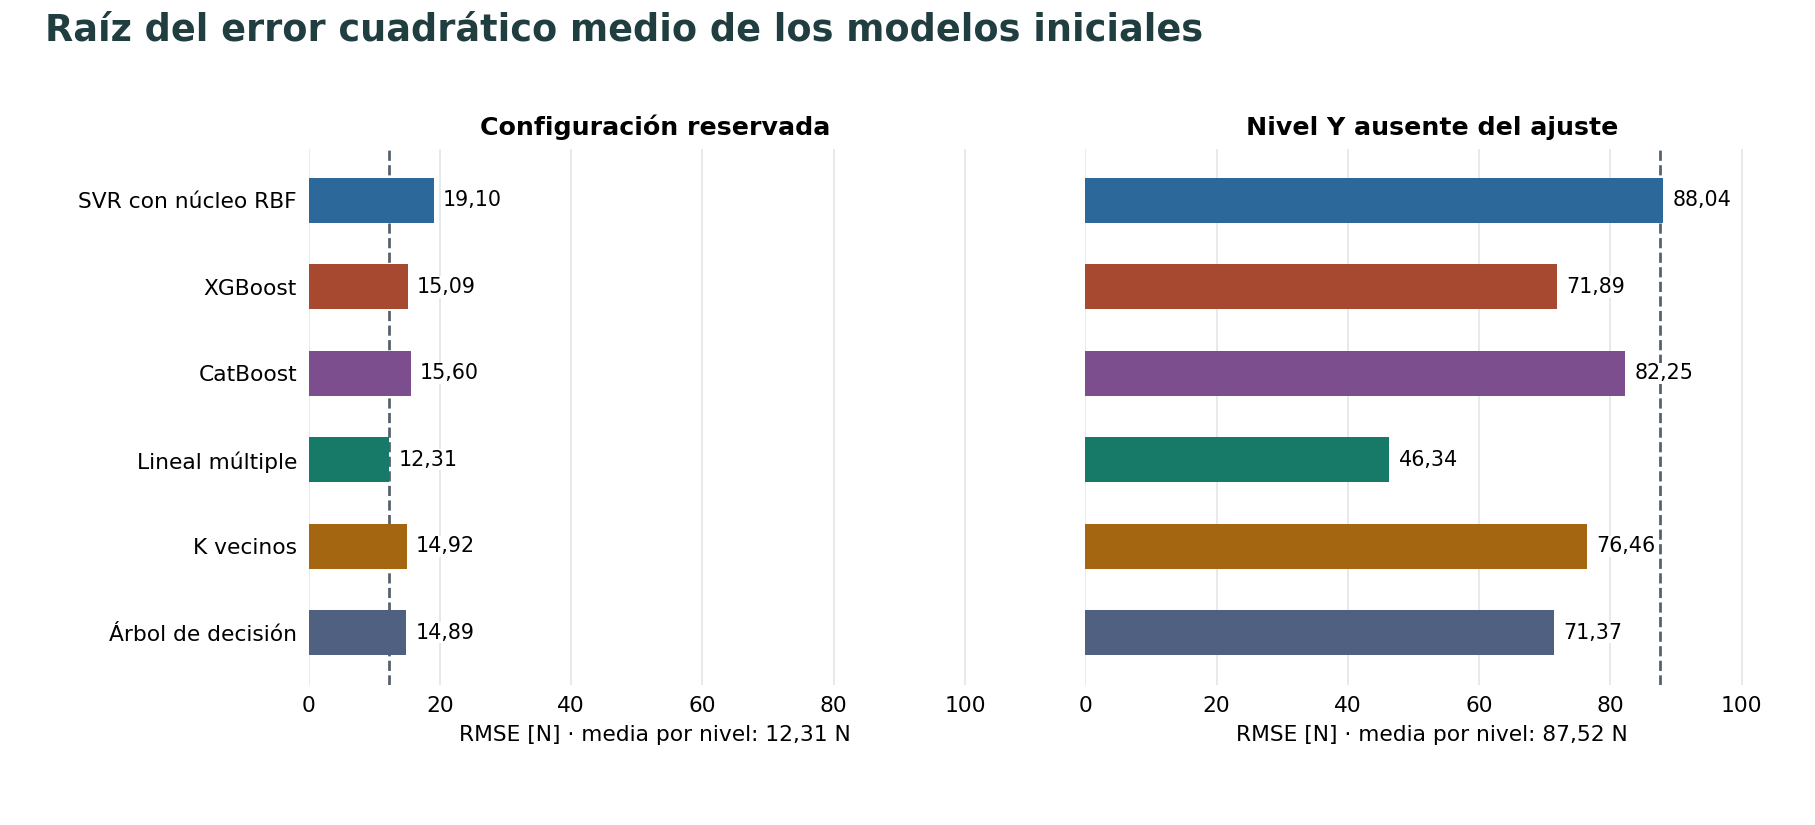

In [40]:
graficas.mostrar(graficas.error_por_modelo, metricas, "RMSE_N")

Cada barra muestra la raíz del promedio de los errores al cuadrado. Un error grande pesa más en el RMSE que en el MAE. La línea discontinua indica el RMSE de la media por nivel.

In [41]:
vista.leer_rmse(principal, valor("configuracion", "Media_por_nivel", "RMSE_N"))

  Interpretación. En configuraciones reservadas, Lineal múltiple alcanza un RMSE de   
  12,3078 N y la media por nivel, 12,3084 N. Al dar más peso a los errores grandes,   
  ambos procedimientos quedan separados por 0,00054 N.                                

### 4.3 Brecha entre entrenamiento y prueba y distribución del error

La primera gráfica promedia los MAE de cada pliegue con el mismo peso. Una brecha amplia señala que el modelo ajusta mejor las geometrías vistas que las reservadas. La segunda gráfica examina los errores individuales. Una mediana baja junto a un percentil 90 alto indica que los casos con mayor error pueden cambiar la clasificación por MAE.

In [42]:
ajuste_y_reserva = graficas.resumir_ajuste(folds)

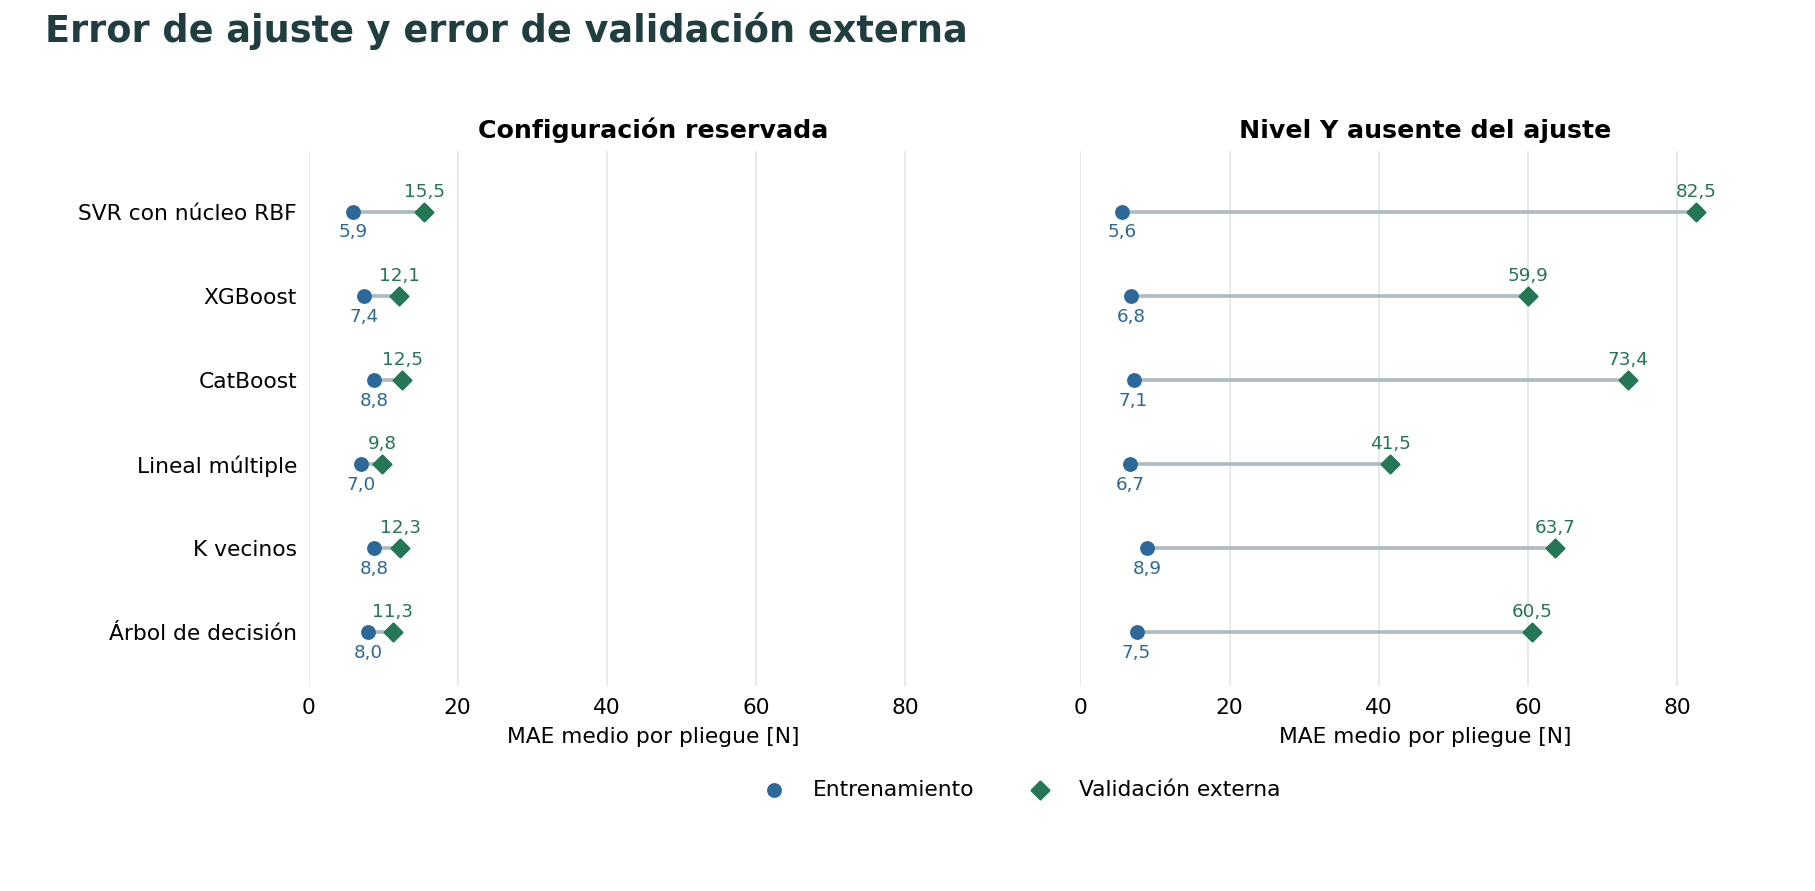

In [43]:
graficas.mostrar(graficas.ajuste_y_validacion, ajuste_y_reserva)

El círculo muestra el MAE sobre las geometrías usadas para ajustar el modelo y el rombo, el MAE sobre las reservadas. Cada pliegue aporta el mismo peso. La longitud del segmento mide cuánto cambia el error al pasar de ajuste a validación.

In [44]:
vista.leer_brecha(ajuste_y_reserva)

  Interpretación. En configuraciones reservadas, SVR con núcleo RBF pasa de 5,93 N    
  en entrenamiento a 15,48 N en validación. Presenta la mayor brecha (9,55 N) entre   
  las familias iniciales. El ajuste reproduce las geometrías de entrenamiento con     
  mayor precisión que las reservadas.                                                 

In [45]:
iniciales_oof = oof.loc[oof.procedimiento.isin(MODELOS)]
curvas_carga = graficas.resumir_cargas(iniciales_oof)

In [46]:
graficas.mostrar(graficas.carga_observada_predicha, curvas_carga, destino=panel_carga)
vista.leer_observado(panel_interpretacion_2, curvas_carga)
vista.mostrar_errores_maximos(iniciales_oof)

**Mayor error por modelo y protocolo**

| protocolo | procedimiento | observado_N | predicho_N | error_absoluto_N |
| :--- | :--- | ---: | ---: | ---: |
| configuracion | Arbol_decision | 47,550 | 98,086 | 50,536 |
| configuracion | CatBoost | 47,550 | 94,789 | 47,239 |
| configuracion | KNN | 208,740 | 179,807 | 28,933 |
| configuracion | Lineal_multiple | 47,550 | 77,831 | 30,281 |
| configuracion | SVR_RBF | 47,550 | 99,211 | 51,661 |
| configuracion | XGBoost | 47,550 | 94,693 | 47,143 |
| familia | Arbol_decision | 215,520 | 94,560 | 120,960 |
| familia | CatBoost | 215,520 | 94,486 | 121,034 |
| familia | KNN | 215,520 | 91,553 | 123,967 |
| familia | Lineal_multiple | 193,200 | 104,411 | 88,789 |
| familia | SVR_RBF | 215,520 | 88,384 | 127,136 |
| familia | XGBoost | 212,430 | 88,981 | 123,449 |

In [47]:
percentiles_error = graficas.percentiles_por_probeta(oof)

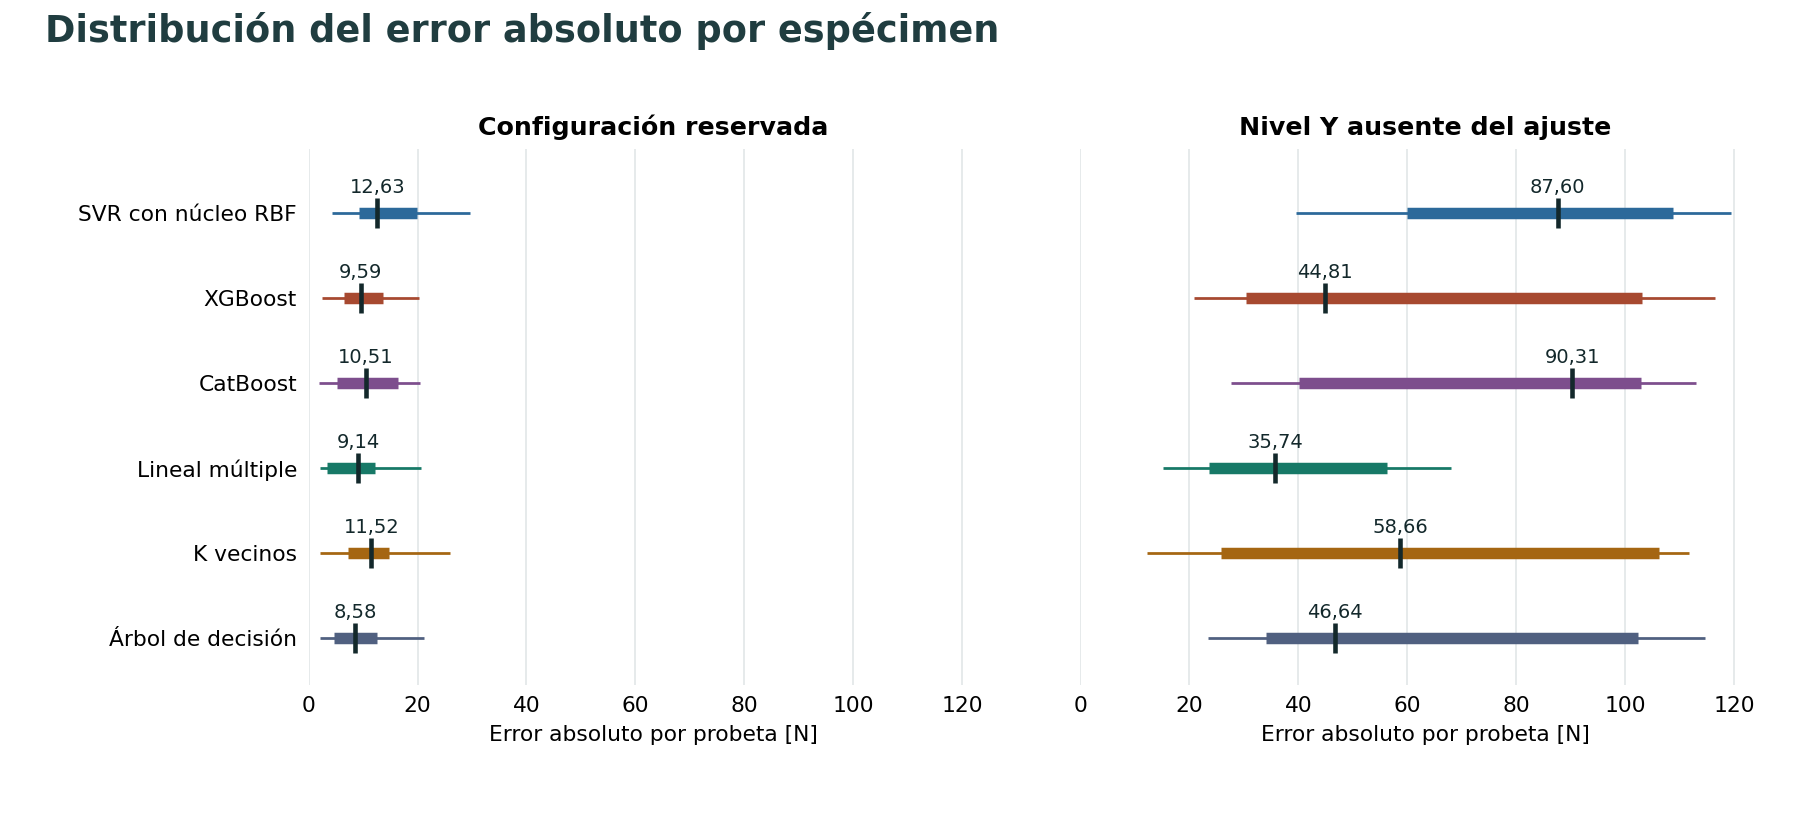

In [48]:
graficas.mostrar(graficas.distribucion_errores, percentiles_error)

Cada línea resume los errores absolutos individuales de un modelo. La marca central indica la mediana, el trazo grueso abarca los percentiles 25 a 75 y el fino los percentiles 10 a 90.

In [49]:
vista.leer_distribucion(percentiles_error, mejor)

  Interpretación. En configuraciones reservadas, Árbol de decisión tiene la menor     
  mediana del error absoluto (8,58 N), pero su percentil 90 alcanza 21,13 N. Cuando   
  se promedian todos los errores absolutos, el menor MAE corresponde a Lineal         
  múltiple.                                                                           

## 5. Ajuste de hiperparámetros con búsqueda aleatoria discreta

### 5.1 Validación cruzada anidada por grupos

**La estrategia combina una preselección de familias con una búsqueda aleatoria sin reemplazo.** Primero se aparta del entrenamiento la configuración o el nivel Y que servirá de prueba externa. Dentro del entrenamiento restante se eligen familia e hiperparámetros mediante validación interna según el protocolo.

- Para una **configuración nominal reservada**, `GroupKFold(n_splits=5)` mantiene juntas las probetas con la misma configuración, sin barajar los grupos. [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)
- Para un **nivel celular Y reservado**, `LeaveOneGroupOut` aparta por turno cada nivel disponible en el entrenamiento externo. [LeaveOneGroupOut](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneGroupOut.html)

Cada ajuste interno vuelve a estimar el preprocesamiento. El MAE interno es el promedio de los errores absolutos de las predicciones reservadas internas, con el mismo peso por probeta.

In [50]:
def datos_internos(train, protocolo):
    """Prepara una sola vez los grupos y las reservas que comparten el cribado y la búsqueda."""
    X_train, y_train = X.iloc[train], y.iloc[train]
    if protocolo == "configuracion":
        grupos = nominal[train]
        separador = GroupKFold(n_splits=5)
        etiquetas = grupos
    elif protocolo == "familia":
        grupos = X_train.n_cells_Y.to_numpy()
        separador = LeaveOneGroupOut()
        etiquetas = grupos.astype(int).astype(str)
    else:
        raise ValueError(f"Protocolo desconocido: {protocolo}")
    pliegues = list(separador.split(X_train, groups=etiquetas))
    return X_train, y_train, grupos, pliegues

### 5.2 Preselección de familias con sus parámetros iniciales

El cribado evalúa las configuraciones iniciales de cinco familias ajustables (SVR, XGBoost, CatBoost, K vecinos y árbol de decisión). Mínimos cuadrados se conserva con intercepto y base independiente como referencia lineal fija. Para elegir cada una de las dos plazas se toma el mejor MAE interno entre las familias restantes y se admiten las que están a **1 N o menos** de él.

Dentro de esa banda se elige la familia con menor dispersión entre grupos. Para medirla, se calcula el MAE de cada grupo y la mediana de sus desviaciones absolutas respecto de la mediana grupal (MAD). En caso de empate se prefiere menor MAE y luego el orden prefijado (árbol, K vecinos, SVR, XGBoost y CatBoost). Se retira la familia elegida y se repite la regla para la segunda plaza.

In [51]:
def inner_metrics(y: np.ndarray, pred: np.ndarray, groups: np.ndarray) -> tuple[float, float]:
    """MAE pooled por caso y MAD no escalada de las MAE por grupo."""
    errors = np.abs(np.asarray(y) - np.asarray(pred))
    means = pd.Series(errors).groupby(np.asarray(groups)).mean()
    return (float(errors.mean()), float(np.median(np.abs(means - np.median(means)))))


def rank_families(scores: dict[str, tuple[float, float]], cfg: Params) -> list[str]:
    """Ordena por banda de MAE, estabilidad interna y orden congelado."""
    remaining = dict(scores)
    order = []
    while remaining:
        limit = min((v[0] for v in remaining.values())) + cfg['banda_cribado_N']
        eligible = [f for f, v in remaining.items() if v[0] <= limit + 1e-12]
        chosen = min(eligible,
            key=lambda f: (remaining[f][1], remaining[f][0], cfg['orden_complejidad'].index(f), f))
        order.append(chosen)
        del remaining[chosen]
    return order

In [52]:
def registrar_reservas_internas(X, y, groups, splits, context, rows):
    if not X.index.equals(y.index) or len(groups) != len(X):
        raise ValueError('Índices internos incongruentes.')
    seen = []
    for s, (tr, va) in enumerate(splits, 1):
        if set(tr) & set(va) or set(groups[tr]) & set(groups[va]) or set(tr) | set(va) != set(range(len(X))):
            raise ValueError('Fuga en partición interna.')
        seen.extend(va)
        rows['particiones_internas'].append({**context, 'split': s, 'casos_train': _ids(X.index[tr]),
            'casos_validacion': _ids(X.index[va]), 'grupos_train': _object(sorted(set(groups[tr]))),
            'grupos_validacion': _object(sorted(set(groups[va])))})
    if sorted(seen) != list(range(len(X))):
        raise ValueError('Cobertura interna OOF incompleta.')

In [53]:
def evaluar_internamente(family, order, params, X, y, groups, splits, cfg, context, rows) -> tuple[tuple[float, float], float]:
    start = perf_counter()
    p = np.full(len(X), np.nan)
    ids, medido = X.index.to_numpy(), y.to_numpy()
    cid = f'{family}_{order:02d}'
    for s, (tr, va) in enumerate(splits, 1):
        c = {**context, 'split': s, 'etapa_ajuste': 'cribado' if order == 0 else 'busqueda', 'config_id': cid}
        obj, _ = _fit(family, params, cfg, X.iloc[tr], y.iloc[tr], c, rows)
        p[va], _ = _predict(obj, X.iloc[va])
        for j in va:
            rows['predicciones_internas'].append({**c, 'familia_real': family, 'Case_n': int(ids[j]),
                'grupo_interno': groups[j], 'observado_N': float(medido[j]), 'predicho_N': float(p[j])})
    return (inner_metrics(medido, p, groups), perf_counter() - start)

In [54]:
def cribar_entrenamiento(X, y, groups, splits, cfg, context, rows):
    started = perf_counter()
    registrar_reservas_internas(X, y, groups, splits, context, rows)
    familias = [f for f in INITIAL if f in cfg["espacios"]]
    screen = {f: evaluar_internamente(f, 0, cfg["parametros_iniciales"][f],
              X, y, groups, splits, cfg, context, rows) for f in familias}
    ranking = rank_families({f: v[0] for f, v in screen.items()}, cfg)
    shortlisted = ranking[:cfg['numero_familias_tuning']]
    for rank, f in enumerate(ranking, 1):
        (mae, mad), secs = screen[f]
        rows['cribado_interno'].append({**context, 'familia_real': f, 'MAE_interno_N': mae,
            'MAD_grupos_N': mad, 'rango_cribado': rank, 'elegible_tuning': True,
            'seleccionada_tuning': f in shortlisted, 'tiempo_s': secs})
    return screen, shortlisted, perf_counter() - started

In [55]:
planes_internos, cribados = {}, {}
with threadpool_limits(limits=1):
    for protocolo, reservas in splits.items():
        for fold, (train, _) in enumerate(reservas, 1):
            clave = (protocolo, fold)
            contexto = {"protocolo": protocolo, "fold": fold}
            planes_internos[clave] = datos_internos(train, protocolo)
            cribados[clave] = cribar_entrenamiento(*planes_internos[clave], cfg, contexto, rows)

cribado = pd.DataFrame(rows["cribado_interno"])
seleccion = cribado.loc[cribado.seleccionada_tuning].copy()
resultado["seleccion"] = seleccion

In [56]:
vista.mostrar_familias(seleccion, "Familias que pasaron al ajuste")

| Protocolo | Familias que pasaron al ajuste |
| :--- | :--- |
| Configuración reservada | Árbol de decisión, CatBoost, K vecinos, XGBoost |
| Nivel Y ausente del ajuste | CatBoost, K vecinos, SVR con núcleo RBF |

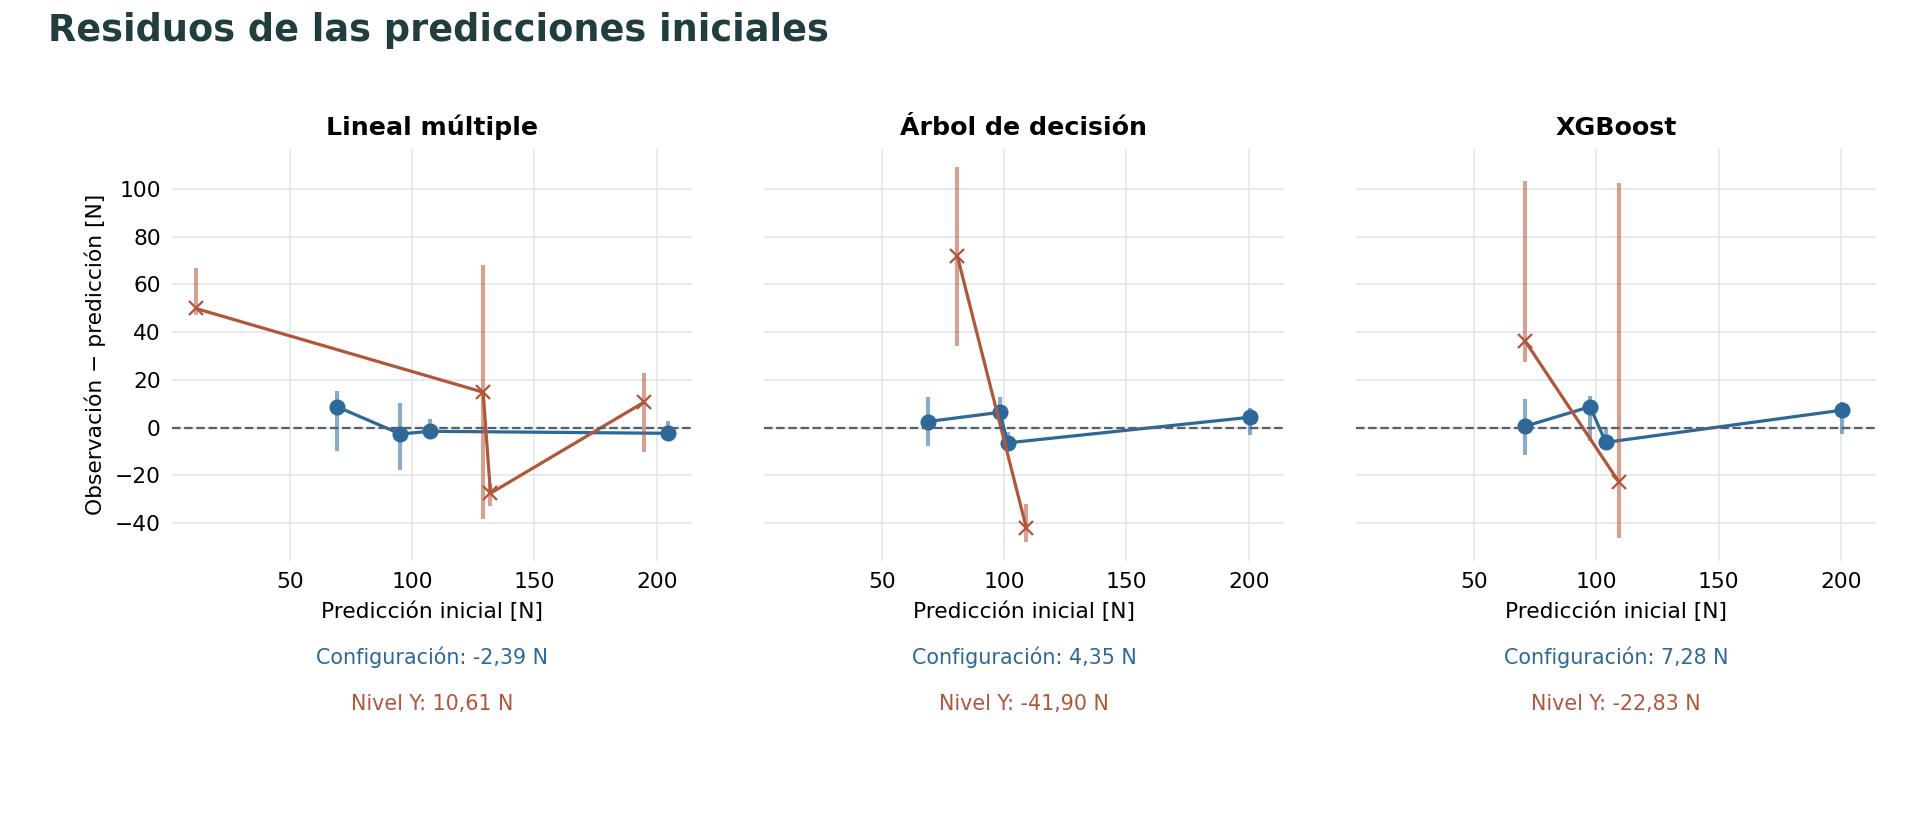

In [57]:
tramos_residuales = graficas.residuos_por_tramo(oof, metricas, seleccion)
graficas.mostrar(graficas.residuos, tramos_residuales)

El residuo se calcula como carga observada menos carga predicha. Un valor positivo indica subestimación y uno negativo, sobreestimación. El signo es el inverso del sesgo global de la tabla. Las marcas son las medianas y las barras abarcan los cuartiles centrales de los residuos en cada tramo de carga predicha.

In [58]:
vista.leer_residuos(tramos_residuales)

  Interpretación. En el tramo de predicciones más altas de Lineal múltiple, el        
  residuo mediano fue -2,39 N al reservar configuraciones y 10,61 N al retirar un     
  nivel Y. En la zona alta, el modelo pasa de sobreestimar con niveles conocidos a    
  subestimar cuando se retira un nivel.                                               

### 5.3 Muestreo de hiperparámetros sin reemplazo

Para cada familia se forma el producto de los valores permitidos en la tabla. La configuración inicial ocupa la primera posición. Entre las combinaciones restantes se sortean **siete distintas con igual probabilidad**, con `Generator.choice(..., replace=False)`. Así, cada familia seleccionada evalúa **ocho configuraciones** con los mismos pliegues internos. [Muestreo con NumPy](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)

Los planes se fijan antes de observar los resultados y se reutilizan en las distintas reservas. La semilla del sorteo es **20261106 más la posición de la familia**, contada desde cero en el orden SVR, XGBoost, CatBoost, lineal, K vecinos y árbol. La familia lineal conserva su posición aunque se evalúa con su configuración fija. En K vecinos se exploran $k$, pesos uniformes o inversos a la distancia y distancias Manhattan ($p=1$) o euclídeas ($p=2$).

In [59]:
orden_parametros = {
    "SVR_RBF": ("C", "epsilon", "gamma"),
    "XGBoost": ("max_depth", "n_estimators", "learning_rate", "min_child_weight", "reg_lambda"),
    "CatBoost": ("iterations", "depth", "learning_rate", "l2_leaf_reg"),
    "KNN": ("n_neighbors", "weights", "p"),
    "Arbol_decision": ("max_depth", "min_samples_leaf"),
}
assert all(set(orden_parametros[f]) == set(cfg["espacios"][f]) for f in orden_parametros)


def freeze_candidates(cfg: Params) -> dict[str, list[Params]]:
    """Muestrea una vez cada pequeño espacio, sin y, folds ni resultados."""
    result = {}
    for i, family in enumerate(INITIAL):
        if family not in cfg['espacios']:
            continue
        fixed = cfg['parametros_iniciales'][family]
        space = cfg['espacios'][family]
        keys = list(orden_parametros[family])
        pool = [dict(fixed, **dict(zip(keys, row))) for row in product(*(space[k] for k in keys))]
        pool = [p for p in pool if p != fixed]
        rng = np.random.default_rng(cfg['semilla'] + i)
        inds = rng.choice(len(pool), size=cfg['presupuesto_por_candidata'] - 1, replace=False)
        result[family] = [fixed.copy(), *[pool[j] for j in inds]]
    return result

draws = freeze_candidates(cfg)  # Usa solo la semilla y el espacio publicados en la configuración.
assert len(draws) == 5 and all(len(candidates) == 8 for candidates in draws.values())

In [60]:
presupuesto = cfg["presupuesto_por_candidata"]
vista.mostrar_espacios(cfg, draws)

| Modelo | Espacio discreto | Configuraciones por búsqueda |
| :--- | :--- | ---: |
| SVR con núcleo RBF | {"C": [25, 100, 250], "epsilon": [2, 5, 10], "gamma": ["scale", 0.03, 0.3]} | 8 |
| XGBoost | {"max_depth": [1, 2, 3], "n_estimators": [40, 60, 80], "learning_rate": [0.03, 0.075, 0.15], "min_child_weight": [1, 2, 4], "reg_lambda": [1, 3, 10]} | 8 |
| CatBoost | {"iterations": [40, 60, 80], "depth": [1, 2, 3], "learning_rate": [0.03, 0.075, 0.15], "l2_leaf_reg": [2, 5, 12]} | 8 |
| K vecinos | {"n_neighbors": [2, 3, 4, 5, 7], "weights": ["uniform", "distance"], "p": [1, 2]} | 8 |
| Árbol de decisión | {"max_depth": [1, 2, 3], "min_samples_leaf": [2, 3, 4]} | 8 |

Se evalúan 8 configuraciones por familia candidata con semilla base 20261106.

### 5.4 Elección de hiperparámetros y predicción del grupo reservado

Para cada familia preseleccionada se eligen los parámetros con menor MAE interno. Si dos opciones quedan a `1e−10` N o menos del mínimo, gana la menor MAD entre grupos y, si persiste el empate, la primera en el plan de búsqueda. El selector aplica la misma regla entre las dos familias ganadoras, con el orden del cribado como último desempate.

Solo entonces se reajusta el modelo sobre todo el entrenamiento externo y se predice el grupo que quedó apartado. Para medir cuánto aportó el ajuste se compara esa predicción con la obtenida por **la misma familia**, con sus parámetros iniciales y sobre la misma probeta.

In [61]:
def best_index(losses: list[tuple[float, float]]) -> int:
    """Menor MAE; empate numérico por MAD y orden del plan."""
    minimum = min((x[0] for x in losses))
    return min((i for i, v in enumerate(losses) if v[0] <= minimum + 1e-10), key=lambda i: (losses[i][1], i))

In [62]:
def afinar(X, y, groups, splits, cfg, draws, context, rows, cribado_previo):
    screen, shortlisted, seconds_screen = cribado_previo
    started = perf_counter()
    winners = []
    for rank, f in enumerate(shortlisted, 1):
        values = [screen[f]] + [evaluar_internamente(f, i, draws[f][i], X, y, groups, splits, cfg, context, rows) for i in range(1, len(draws[f]))]
        idx = best_index([s for s, _ in values])
        best = np.inf
        for i, ((mae, mad), secs) in enumerate(values):
            best = min(mae, best)
            rows['busqueda_interna'].append({**context, 'familia_real': f, 'orden': i + 1,
                'config_id': f'{f}_{i:02d}', 'parametros_json': _object(draws[f][i]), 'MAE_interno_N': mae,
                'MAD_grupos_N': mad, 'mejor_acumulado_N': best, 'seleccionada': i == idx,
                'tiempo_s': secs if i else 0.0, 'reuso_cribado': i == 0})
        (mae, mad), _ = values[idx]
        winners.append({'rango_cribado': rank, 'familia_real': f, 'config_id': f'{f}_{idx:02d}',
            'parametros': draws[f][idx], 'MAE_interno_N': mae, 'MAD_grupos_N': mad})
    chosen = best_index([(w['MAE_interno_N'], w['MAD_grupos_N']) for w in winners])
    for i, w in enumerate(winners):
        rows['seleccion_tuning'].append({**context, **{k: v for k, v in w.items() if k != 'parametros'},
            'parametros_json': _object(w['parametros']), 'elegida_selector': i == chosen})
    return (winners, chosen, seconds_screen + perf_counter() - started)

In [63]:
with threadpool_limits(limits=1):
    for protocolo, reservas in splits.items():
        for fold, (tr, te) in enumerate(reservas, 1):
            clave = (protocolo, fold)
            ctx = {"protocolo": protocolo, "fold": fold}
            plan = planes_internos[clave]
            X_train, y_train = plan[:2]
            X_test = X.iloc[te]
            ganadoras, elegida, t_busqueda = afinar(*plan, cfg, draws, ctx, rows, cribados[clave])
            for puesto, receta_fold in enumerate(ganadoras):
                familia = receta_fold["familia_real"]
                ajuste = {**ctx, "etapa_ajuste": "externa_optimizada", "config_id": receta_fold["config_id"]}
                modelo, t_ajuste, pred, t_pred, pred_train = evaluar_reserva(
                    familia, receta_fold["parametros"], X_train, y_train, X_test, ajuste, cfg, rows)
                inicial = cache[protocolo, fold, familia]
                procedimiento = ADAPT[puesto]
                _diagnose(modelo, familia, X_train, X_test, {**ctx, "procedimiento": procedimiento}, rows)
                procedimientos = (procedimiento, ADAPT[2]) if puesto == elegida else (procedimiento,)
                for proc in procedimientos:
                    _record(proc, familia, ctx, X, y, tr, te, nominal, pred, pred_train,
                            t_ajuste, t_pred, t_busqueda, inicial, rows)

### 5.5 Reajuste de la configuración seleccionada

Para preparar el uso posterior se repiten la preselección y la búsqueda con toda la campaña, agrupando por configuración nominal. Los errores del apartado 7 proceden de las reservas externas del procedimiento anidado. Comprobar el rendimiento de esta configuración final en ensayos futuros requiere una evaluación independiente.

In [64]:
tr = np.arange(len(X))
ctx = {"protocolo":"campana_completa", "fold":0}
modelos_campana = {}
with threadpool_limits(limits=1):
    _, _, _, internos = datos_internos(tr, "configuracion")
    elegibles = cribar_entrenamiento(X, y, nominal, internos, cfg, ctx, rows)
    winners, chosen, _ = afinar(X, y, nominal, internos, cfg, draws, ctx, rows, elegibles)
    for w in winners:
        f = w["familia_real"]
        modelos_campana[f], _ = _fit(
            f, w["parametros"], cfg, X, y,
            {**ctx,"etapa_ajuste":"reajuste_campana","config_id":w["config_id"]}, rows)
receta = {
    "protocolo":"configuracion", "casos_train":X.index.tolist(), "feature_set":"A",
    "alcance":"Reajuste con todos los especímenes observados; sin evaluación externa nueva.",
    "candidatas":winners, "selector":winners[chosen],
}

In [65]:
rows["metricas_resumen"].clear()
_summarize(rows)
frames = {nombre_tabla: pd.DataFrame(filas) for nombre_tabla, filas in rows.items()}
resultado = {
    "metricas": frames["metricas_resumen"], "oof": frames["predicciones_oof"],
    "folds": frames["metricas_folds"], "busqueda": frames["busqueda_interna"],
    "cribado": frames["cribado_interno"], "seleccion": frames["seleccion_tuning"],
}
metricas, oof, folds = (resultado[k] for k in ("metricas","oof","folds"))
busqueda, seleccion, cribado = (
    resultado[k].loc[resultado[k].protocolo.isin(PROTOCOLOS)].copy()
    for k in ("busqueda", "seleccion", "cribado")
)
assert busqueda.groupby(["protocolo", "fold", "familia_real"]).size().eq(presupuesto).all()
assert len(oof) == len(X) * len(PROTOCOLOS) * (len(INITIAL) + len(REFS) + len(ADAPT))
assert not oof.duplicated(["protocolo", "procedimiento", "Case_n"]).any()
duracion_motor_s = perf_counter() - started

In [66]:
# Las tablas iniciales y finales comparten una única matriz de MAE externo.
mae_externo = metricas.pivot(index="procedimiento", columns="protocolo", values="MAE_N")
metricas_nominales = metricas.loc[metricas.protocolo.eq("configuracion")].set_index("procedimiento")

externas_ajustadas = oof.loc[oof.procedimiento.isin(ADAPT)].copy()
externas_ajustadas["inicial"] = (externas_ajustadas.predicho_inicial_misma_familia_N
                                 - externas_ajustadas.observado_N).abs()
mae_pareado = (externas_ajustadas.groupby(["procedimiento", "protocolo"])
               .agg(inicial=("inicial", "mean"), ajustada=("error_absoluto_N", "mean")))
vista.actualizar_portada(panel_baselines, portada_resultados, panel_comparaciones, metricas_nominales,
                       mae_externo, mae_pareado, REFS, ADAPT)

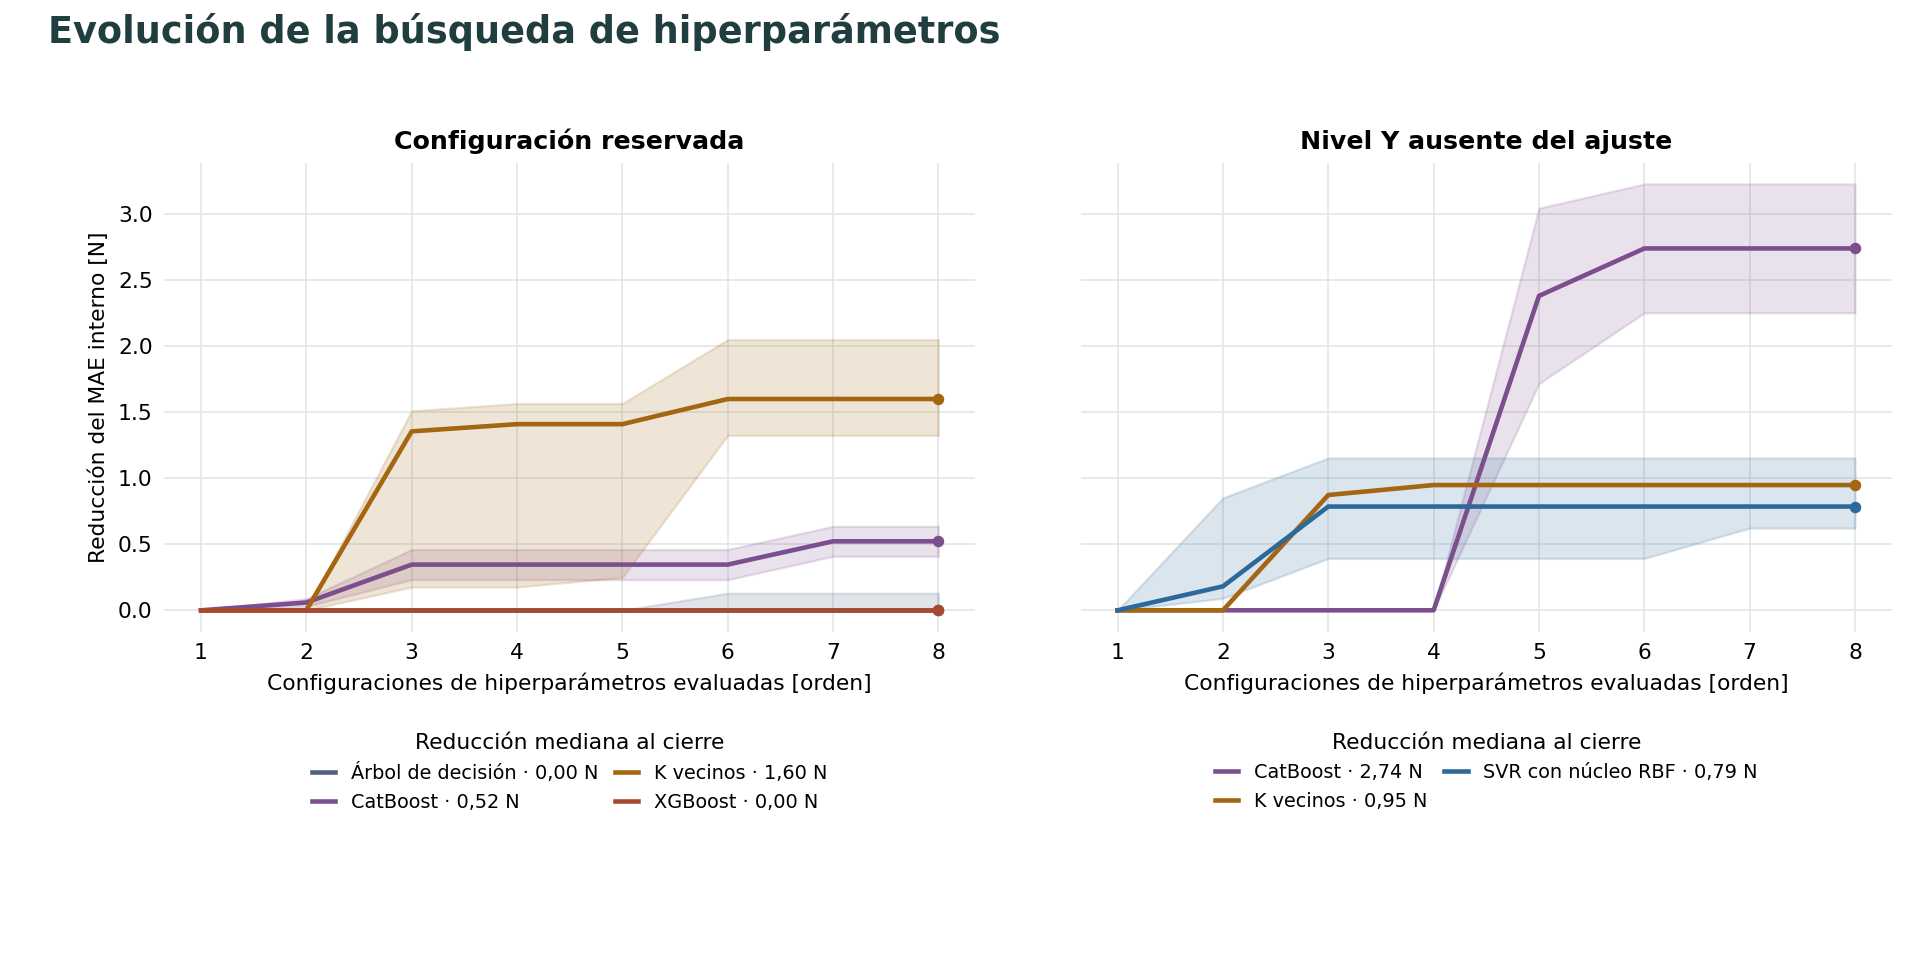

In [67]:
progreso_interno = graficas.progreso_busqueda(busqueda)
graficas.mostrar(graficas.evolucion_busqueda, progreso_interno)

Cada punto muestra cuánto bajó el mejor MAE interno respecto de la primera configuración de hiperparámetros evaluada. La línea resume la mediana entre reservas y la banda, los cuartiles centrales.

In [68]:
vista.leer_busqueda(progreso_interno)

  Interpretación. La mayor reducción mediana del MAE interno al cierre fue la de K    
  vecinos (1,60 N) al reservar configuraciones y la de CatBoost (2,74 N) al retirar   
  niveles Y. Estas mejoras corresponden al entrenamiento. La comparación del MAE      
  antes y después del ajuste evalúa su efecto sobre las reservas externas.            

In [69]:
vista.mostrar_familias(seleccion.loc[seleccion.elegida_selector], "Familias elegidas por la validación interna")
vista.mostrar_reajuste(receta, cfg)

| Protocolo | Familias elegidas por la validación interna |
| :--- | :--- |
| Configuración reservada | Árbol de decisión, CatBoost, K vecinos, XGBoost |
| Nivel Y ausente del ajuste | SVR con núcleo RBF |

Reajuste con la campaña completa, Árbol de decisión, {'max_depth': 2, 'min_samples_leaf': 2}.

## 6. Efecto del ajuste y variación del error entre grupos

Las comparaciones mantienen la misma probeta y la misma reserva para cada par de predicciones. Así se distingue el efecto de cambiar el procedimiento del efecto de evaluar una geometría diferente.

### 6.1 Diferencias frente a Ridge, efecto del ajuste y estabilidad

La comparación con Ridge usa la diferencia de errores absolutos en cada probeta. La evaluación del ajuste compara la misma familia antes y después de buscar hiperparámetros. Los percentiles del MAE por pliegue muestran cuánto cambia el desempeño al reservar diferentes grupos.

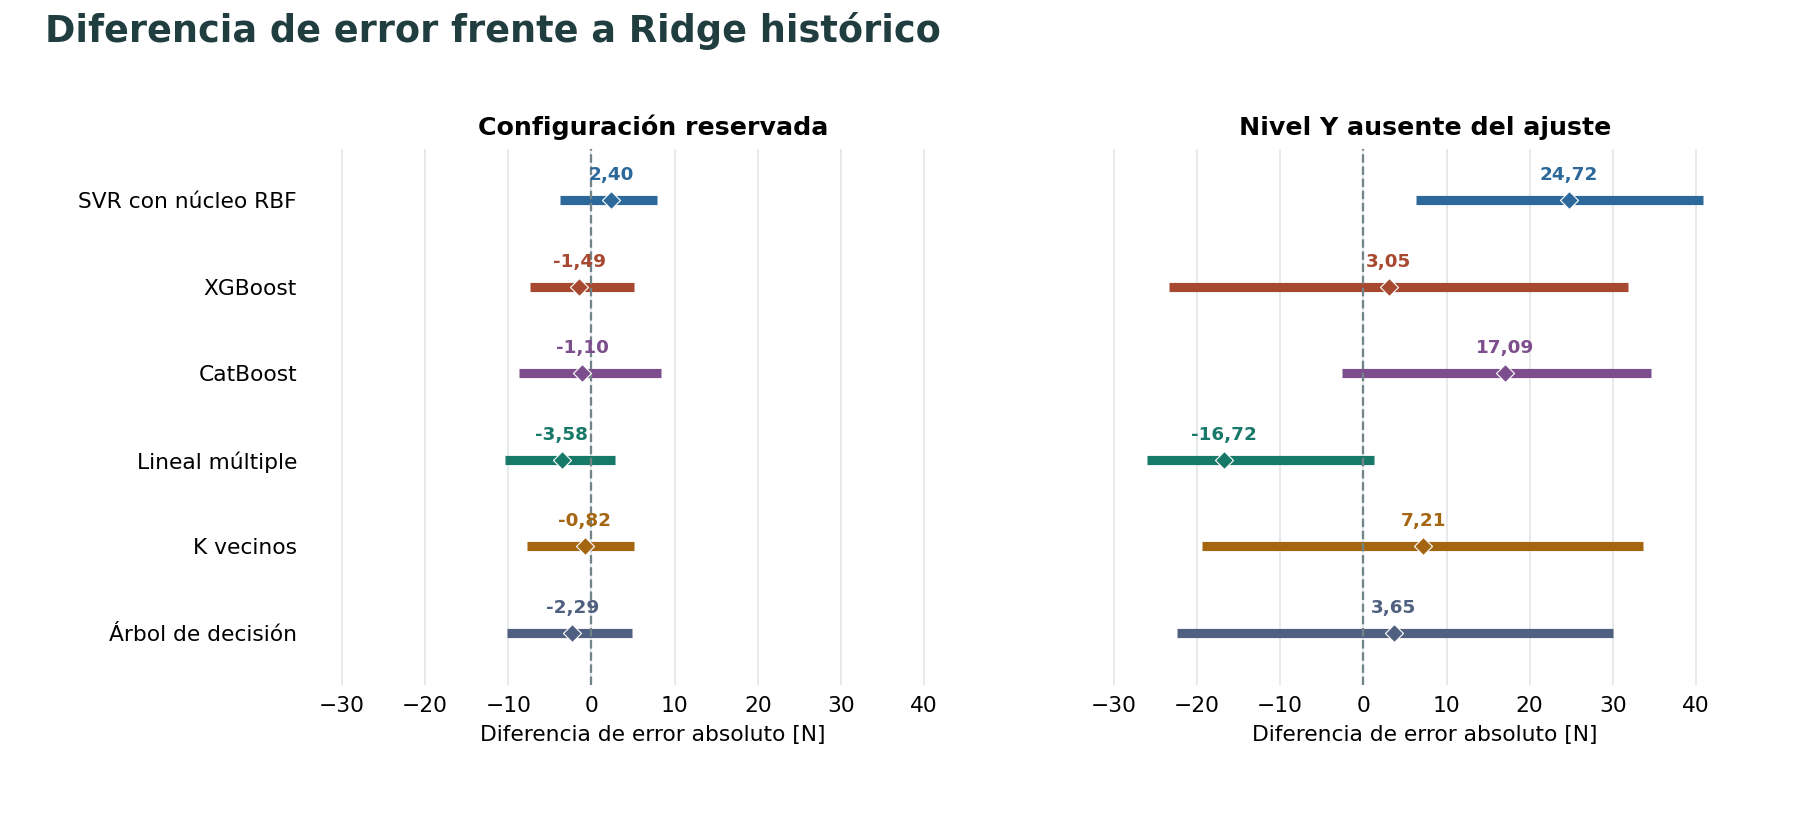

In [70]:
graficas.mostrar(graficas.contraste_ridge, oof)

Para cada probeta se resta el error absoluto de Ridge al del modelo. El rombo indica la media de esas diferencias y el segmento abarca los cuartiles centrales. A la izquierda de cero, el modelo tiene menor error que Ridge.

In [71]:
vista.leer_ridge(principal, transferencia)

  Interpretación. Lineal múltiple presentó la mayor reducción de MAE frente a Ridge   
  al reservar configuraciones (3,58 N). En el protocolo de nivel Y, su diferencia     
  modelo menos Ridge fue -16,72 N. La regresión lineal mejora a Ridge en ambos        
  protocolos de esta campaña.                                                         

In [72]:
vista.mostrar_integrada(metricas, [*REFS, *MODELOS, *ADAPT])

**Configuración reservada · tabla integrada, controles y dos puestos del cribado**

| Modelo | MAE_N | RMSE_N | MedAE_N | R2_OOF | ΔMAE vs Ridge [N] | DE_MAE_fold_N | tiempo_ajuste_s | tiempo_prediccion_s | tiempo_busqueda_s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Mediana de entrenamiento | 49,748 | 64,699 | 35,890 | -0,213 | 36,502 | 41,054 | 0,024 | 0,008 | 0,000 |
| Media por nivel Y | 10,126 | 12,308 | 8,688 | 0,956 | -3,121 | 7,041 | 0,028 | 0,017 | 0,000 |
| Ridge histórico | 13,247 | 16,346 | 11,941 | 0,923 | 0,000 | 9,677 | 0,112 | 0,037 | 0,000 |
| SVR con núcleo RBF | 15,651 | 19,096 | 12,633 | 0,894 | 2,404 | 11,120 | 0,223 | 0,093 | 0,000 |
| XGBoost | 11,754 | 15,093 | 9,594 | 0,934 | -1,493 | 9,947 | 0,508 | 0,094 | 0,000 |
| CatBoost | 12,148 | 15,596 | 10,508 | 0,930 | -1,098 | 10,243 | 1,048 | 0,126 | 0,000 |
| Lineal múltiple | 9,664 | 12,308 | 9,136 | 0,956 | -3,583 | 7,905 | 0,227 | 0,090 | 0,000 |
| K vecinos | 12,429 | 14,923 | 11,515 | 0,935 | -0,818 | 8,104 | 0,206 | 1,795 | 0,000 |
| Árbol de decisión | 10,956 | 14,892 | 8,580 | 0,936 | -2,291 | 10,637 | 0,212 | 0,089 | 0,000 |
| Primera del cribado | 11,263 | 14,643 | 8,757 | 0,938 | -1,984 | 9,825 | 0,198 | 0,069 | 34,334 |
| Segunda del cribado | 13,749 | 18,852 | 9,704 | 0,897 | 0,502 | 12,558 | 0,276 | 0,075 | 34,334 |
| Selector interno | 12,998 | 17,180 | 9,336 | 0,914 | -0,248 | 10,519 | 0,200 | 0,068 | 34,334 |

**Nivel Y ausente del ajuste · tabla integrada, controles y dos puestos del cribado**

| Modelo | MAE_N | RMSE_N | MedAE_N | R2_OOF | ΔMAE vs Ridge [N] | DE_MAE_fold_N | tiempo_ajuste_s | tiempo_prediccion_s | tiempo_busqueda_s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Mediana de entrenamiento | 97,511 | 99,009 | 96,377 | -1,840 | 39,874 | 16,229 | 0,003 | 0,001 | 0,000 |
| Media por nivel Y | 80,593 | 87,521 | 84,392 | -1,219 | 22,955 | 38,870 | 0,003 | 0,002 | 0,000 |
| Ridge histórico | 57,637 | 60,428 | 64,520 | -0,058 | 0,000 | 17,145 | 0,012 | 0,004 | 0,000 |
| SVR con núcleo RBF | 82,358 | 88,039 | 87,602 | -1,246 | 24,720 | 33,871 | 0,027 | 0,012 | 0,000 |
| XGBoost | 60,684 | 71,889 | 44,810 | -0,497 | 3,046 | 44,640 | 0,047 | 0,012 | 0,000 |
| CatBoost | 74,726 | 82,248 | 90,312 | -0,960 | 17,089 | 34,093 | 0,114 | 0,015 | 0,000 |
| Lineal múltiple | 40,915 | 46,337 | 35,745 | 0,378 | -16,723 | 13,564 | 0,028 | 0,012 | 0,000 |
| K vecinos | 64,849 | 76,459 | 58,655 | -0,694 | 7,211 | 41,243 | 0,025 | 0,012 | 0,000 |
| Árbol de decisión | 61,289 | 71,374 | 46,638 | -0,476 | 3,652 | 42,247 | 0,023 | 0,010 | 0,000 |
| Primera del cribado | 81,106 | 87,837 | 88,770 | -1,235 | 23,468 | 37,849 | 0,021 | 0,009 | 2,240 |
| Segunda del cribado | 73,887 | 80,818 | 71,686 | -0,892 | 16,250 | 31,640 | 0,068 | 0,011 | 2,240 |
| Selector interno | 81,106 | 87,837 | 88,770 | -1,235 | 23,468 | 37,849 | 0,021 | 0,009 | 2,240 |

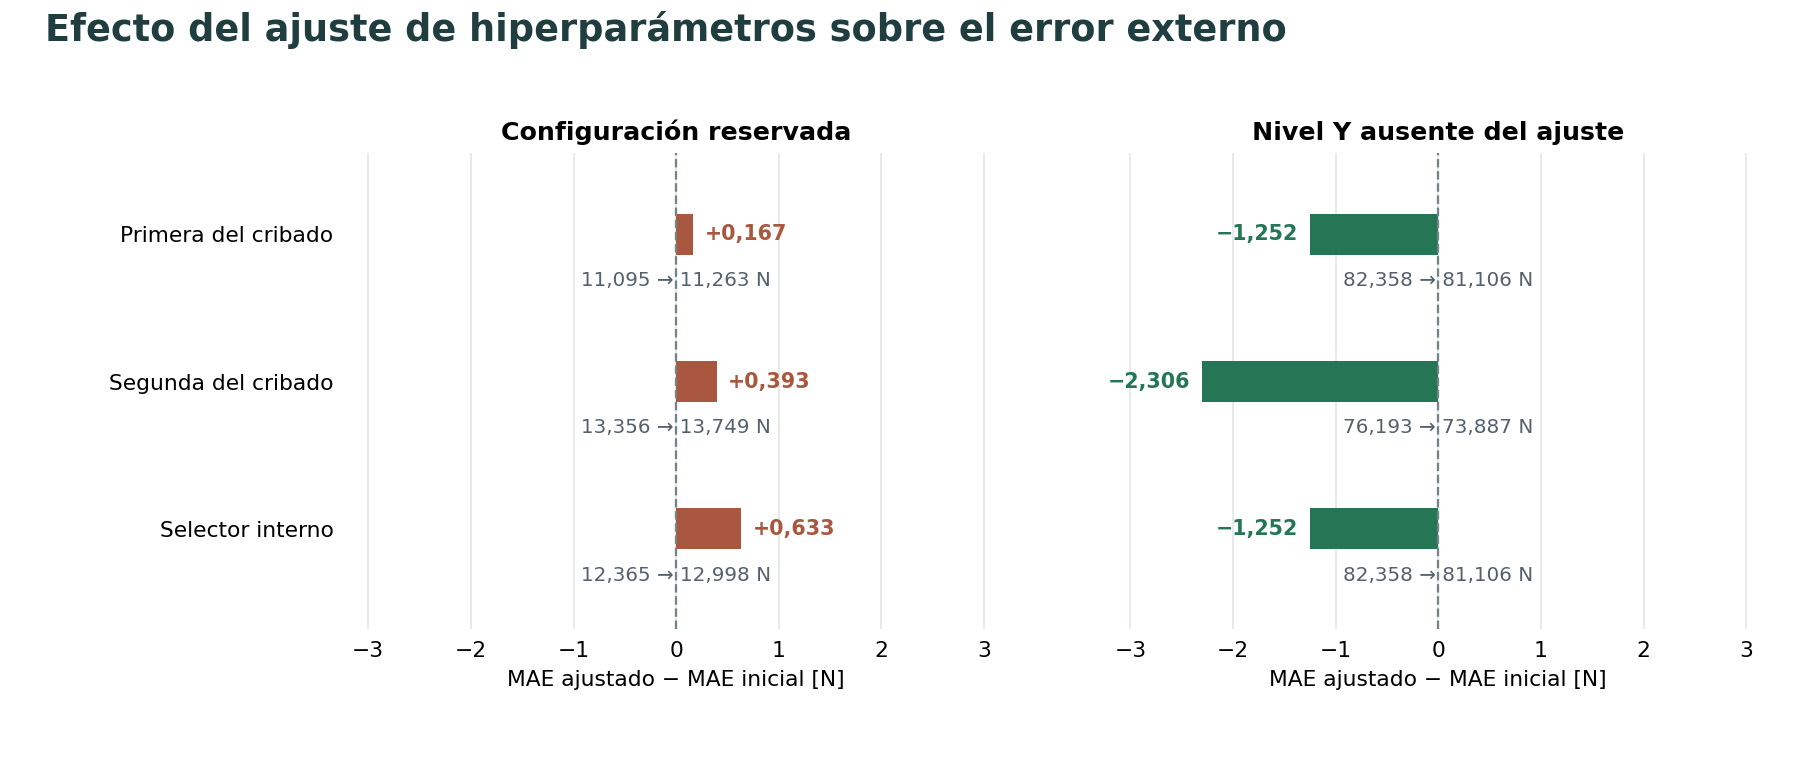

In [73]:
mae_ajuste = mae_pareado.swaplevel().sort_index().rename(columns={"ajustada": "ajustado"})
graficas.mostrar(graficas.efecto_tuning, mae_ajuste)

Cada barra muestra el MAE ajustado menos el MAE inicial de la misma familia, en las mismas probetas reservadas. Un valor negativo indica que la búsqueda redujo el error externo.

In [74]:
vista.leer_efecto_ajuste(mae_ajuste)

  Interpretación. Al reservar configuraciones, el MAE externo del selector aumentó    
  0,633 N (12,365 → 12,998 N). Al retirar un nivel Y, disminuyó 1,252 N (82,358 →     
  81,106 N). El efecto del ajuste depende del grupo que se reserva.                   

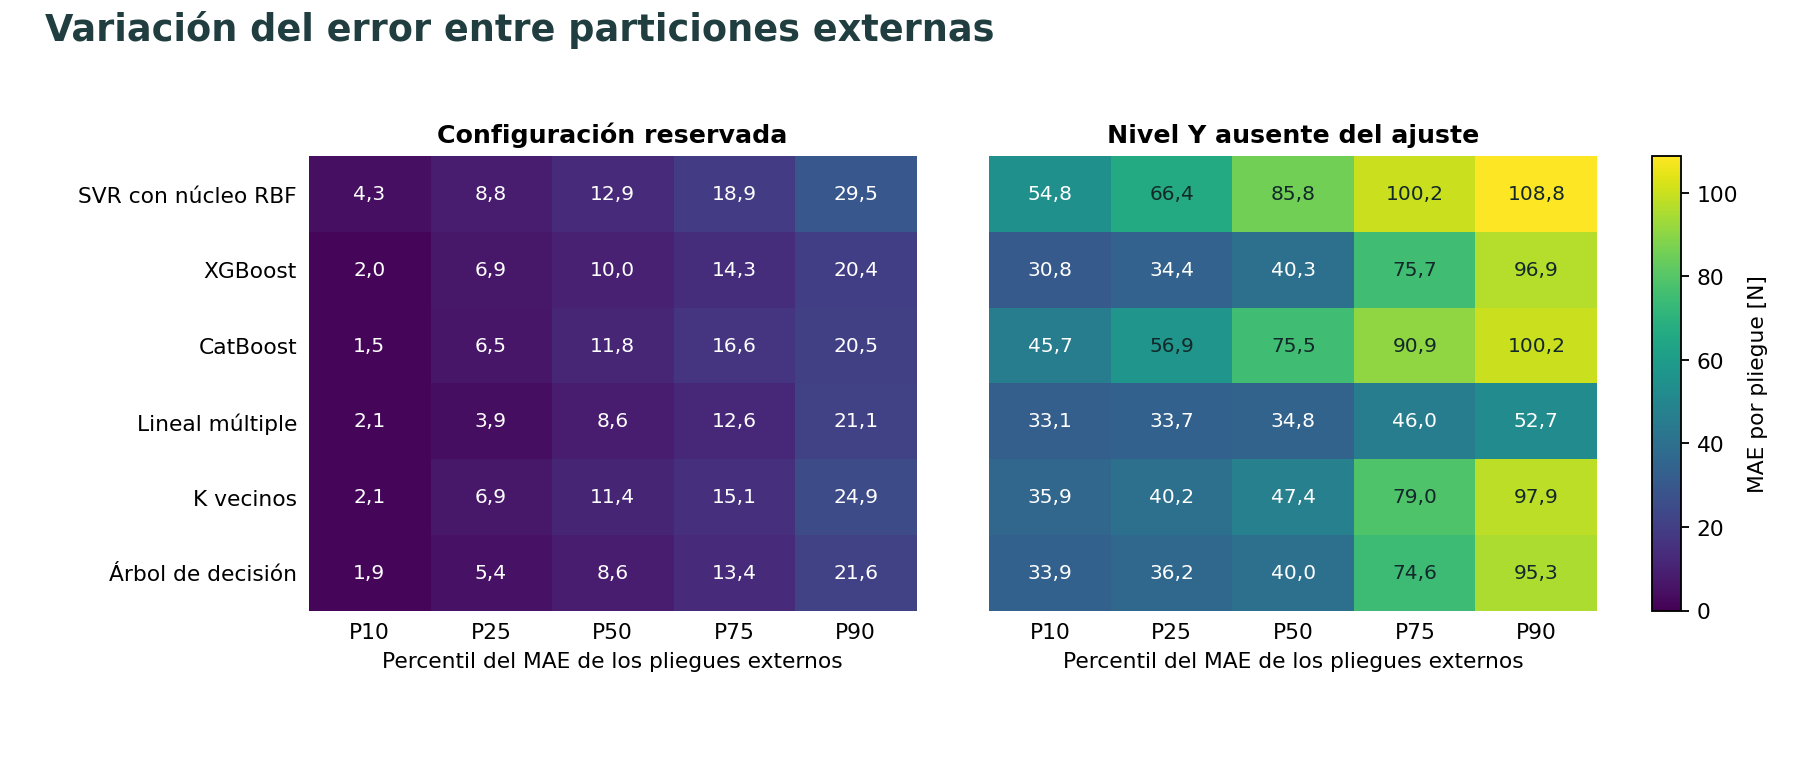

In [75]:
percentiles_pliegue = graficas.percentiles_por_reserva(folds)
graficas.mostrar(graficas.estabilidad, percentiles_pliegue)

Cada celda resume los MAE de los grupos reservados. P50 es la mediana. P90 es el valor por debajo del cual se sitúa aproximadamente el 90 % de esos MAE. Ambos paneles usan la misma escala en newtons.

In [76]:
vista.leer_estabilidad(principal, percentiles_pliegue)

  Interpretación. Para Lineal múltiple, la mediana del MAE por configuración es 8,56  
  N y el percentil 90 alcanza 21,10 N. Al reservar niveles Y, el percentil 90 es      
  52,66 N. El extremo de mayor error es más alto cuando el nivel Y completo queda     
  fuera del entrenamiento.                                                            

### 6.2 Sensibilidad de los modelos a la geometría y a las observaciones extremas

Las pendientes estimadas por pliegue permiten examinar la estabilidad de la base lineal. Las distancias a los vecinos y el número de hojas describen cómo KNN y el árbol generan predicciones locales. Para el modelo principal también se recalcula el MAE omitiendo del promedio la observación de mayor error.

In [77]:
def contraste(oof: pd.DataFrame, candidate: str, base: str) -> dict[str, Any]:
    """Errores emparejados y sensibilidad al grupo en un solo protocolo."""
    if oof.protocolo.nunique()!=1:
        raise ValueError("Comparar un protocolo por vez")
    cols=["Case_n","fold","observado_N","predicho_N"]
    a=oof[oof.procedimiento.eq(candidate)][cols].copy()
    b=oof[oof.procedimiento.eq(base)][cols].copy()
    p=a.merge(b,on=["Case_n","fold"],suffixes=("_a","_b"),validate="one_to_one")
    if len(p)!=len(a) or len(p)!=len(b) or not len(p):
        raise ValueError("Cobertura OOF desigual")
    y=p.observado_N_a.to_numpy()
    if not np.allclose(y,p.observado_N_b,atol=1e-12,rtol=0):
        raise ValueError("Respuesta no comparable")
    ea=np.abs(p.predicho_N_a-y);eb=np.abs(p.predicho_N_b-y)
    d=pd.Series(ea-eb,index=p.index)
    gm=d.groupby(p.fold).mean()
    omit=np.array([d[p.fold.ne(f)].mean() for f in gm.index])
    return {"delta_MAE_N":float(d.mean()),"delta_RMSE_N":float(np.sqrt(np.mean(ea**2))-np.sqrt(np.mean(eb**2))),
            "grupos_mejora":int((gm < -1e-10).sum()),"grupos_empate":int((gm.abs()<=1e-10).sum()),
            "grupos":len(gm),"fraccion_grupos_mejora":float((gm < -1e-10).mean()),
            "delta_al_omitir_grupo_min_N":float(omit.min()),"delta_al_omitir_grupo_max_N":float(omit.max())}


def adopta(c: dict[str,Any], margin: float) -> bool:
    return (c["delta_MAE_N"] <= -margin+1e-10 and c["delta_RMSE_N"] <= 1e-10 and
            c["fraccion_grupos_mejora"]>0.5 and c["delta_al_omitir_grupo_max_N"] < -1e-10)

In [78]:
def lectura_en_memoria(frames, receta, cfg, politica):
    """Distingue menor MAE, recomendación registrada y alternativas no lineales."""
    oof = frames["predicciones_oof"]
    metrics = frames["metricas_resumen"]
    nominal = oof[oof.protocolo.eq("configuracion")]
    m = metrics[metrics.protocolo.eq("configuracion")].set_index("procedimiento")
    f = metrics[metrics.protocolo.eq("familia")].set_index("procedimiento")
    modelos = politica["modelos_iniciales"]
    banda = politica["banda_descriptiva_N"]
    minimo = m.loc[modelos, "MAE_N"].min()
    fijo = next(x for x in politica["prioridad_parsimonia_en_banda"] if m.loc[x,"MAE_N"] <= minimo+banda+1e-10)
    comparacion = contraste(nominal, "Selector_tuning", fijo)
    principal = "Selector_tuning" if adopta(comparacion, banda) else fijo
    frente_a_media = contraste(nominal, principal, "Media_por_nivel")
    operativa = principal if adopta(frente_a_media, banda) else "Media_por_nivel"
    es_selector = principal == "Selector_tuning"
    familia = receta["selector"]["familia_real"] if es_selector else principal
    parametros = receta["selector"]["parametros"] if es_selector else cfg["parametros_iniciales"][principal]
    respaldos = [x for x in m.loc[modelos].sort_values("MAE_N").index if x != familia][:2]
    estrategias = modelos + ["Tuning_rango_1","Tuning_rango_2","Selector_tuning"]
    categorias = {"lineal":"Lineal_multiple","distancias":"KNN",
        "arboles":m.loc[["Arbol_decision","XGBoost","CatBoost"],"MAE_N"].idxmin(),
        "grupo_A_literatura":m.loc[["SVR_RBF","XGBoost","CatBoost"],"MAE_N"].idxmin(),
        "menor_MAE_inicial":m.loc[modelos,"MAE_N"].idxmin(),
        "menor_DE_entre_iniciales":m.loc[modelos,"DE_MAE_fold_N"].idxmin(),
        "menor_MAE_procedimientos_incluido_tuning":m.loc[estrategias,"MAE_N"].idxmin(),
        "menor_MAE_toda_tabla_incluidos_controles":m.MAE_N.idxmin(),"compromiso":principal}
    return {"procedimiento_principal":principal, "familia_principal":familia,
        "parametros_principal":parametros,"respaldos":respaldos,"referencia_operativa":operativa,
        "motivo":"Política de comparación declarada: banda de MAE, dispersión y contraste emparejado por grupo.",
        "MAE_principal_N":float(m.loc[principal,"MAE_N"]), "MAE_media_nivel_N":float(m.loc["Media_por_nivel","MAE_N"]),
        "MAE_referencia_familia_excluida_N":float(f.loc[operativa,"MAE_N"]),
        "MAE_principal_familia_excluida_N":float(f.loc[principal,"MAE_N"]),
        "familia_con_menor_MAE_transferencia":f.loc[modelos,"MAE_N"].idxmin(), "categorias":categorias,
        "procedimiento_fijo_preferido":fijo,"selector_vs_fijo":comparacion,"principal_vs_media_nivel":frente_a_media}

recomendacion = lectura_en_memoria(frames, receta, CFG, LECTURA)

In [79]:
referencia = "Media_por_nivel"
orden_resultados = [
    referencia, "Ridge_historico", "Dummy_mediana",
    *mae_externo.loc[list(MODELOS)].sort_values("configuracion").index,
    "Selector_tuning",
]
errores = mae_externo.loc[orden_resultados, list(PROTOCOLOS)]
delta_baseline = errores.subtract(errores.loc[referencia], axis="columns")

In [80]:
vista.mostrar_pendientes(frames["coeficientes_ols"])

**Pendientes OLS en unidades originales por pliegue**

| variable | unidad_variable | Pendiente mínima | Pendiente mediana | Pendiente máxima |
| :--- | :--- | ---: | ---: | ---: |
| Fiber_base | mm | 2,817 | 10,097 | 19,979 |
| Fiber_height | mm | -9,535 | 0,034 | 12,101 |
| Fiber_total_length | mm | 0,985 | 1,080 | 1,147 |
| Fiber_total_volume | mm³ | 0,221 | 0,258 | 0,282 |
| Pivot_height | mm | -6,767 | 7,185 | 18,777 |
| Sample_total_volume | mm³ | -0,130 | -0,107 | -0,079 |
| n_cells_Y | conteo | -491,441 | -456,683 | -403,235 |

Las pendientes se expresan en la base independiente de cada entrenamiento. La colinealidad limita su interpretación como efectos físicos individuales.

In [81]:
vista.mostrar_diagnostico(recomendacion, frames["diagnosticos_modelos"])

**Comparación por familia y estabilidad**

| Categoría del protocolo principal | Procedimiento |
| :--- | :--- |
| lineal | Lineal múltiple |
| distancias | K vecinos |
| arboles | Árbol de decisión |
| grupo A literatura | XGBoost |
| menor MAE inicial | Lineal múltiple |
| menor DE entre iniciales | Lineal múltiple |
| menor MAE procedimientos incluido tuning | Lineal múltiple |
| menor MAE toda tabla incluidos controles | Lineal múltiple |
| compromiso | Lineal múltiple |

Distancia media a los vecinos en geometría estandarizada: 1,72 por configuración, 4,43 por nivel. El árbol inicial tuvo entre 4 y 4 hojas en configuraciones.

In [82]:
vista.mostrar_sensibilidad(oof, recomendacion["procedimiento_principal"])

Sensibilidad del MAE de Lineal múltiple: al omitir del promedio la observación con mayor error pasa de 9,66 a 8,84 N. Se conservaron todas las probetas.

## 7. Resultados frente a la media por nivel celular

### 7.1 La regresión lineal obtiene el menor MAE al reservar configuraciones

El puesto ordena los modelos iniciales por MAE en configuraciones reservadas. En cada protocolo, $\Delta$ es el MAE del procedimiento menos el de la media por nivel Y. Un valor negativo indica una reducción del error respecto a esa referencia.

In [83]:
vista.mostrar_contraste_baseline(errores, delta_baseline)

| Modelo o referencia | Puesto inicial | MAE config. [N] | Δ vs. baseline [N] | MAE nivel Y [N] | Δ vs. baseline en nivel Y [N] |
| :--- | :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | — | 10,126 | 0,000 | 80,593 | 0,000 |
| Ridge histórico | — | 13,247 | 3,121 | 57,637 | -22,955 |
| Mediana de entrenamiento | — | 49,748 | 39,622 | 97,511 | 16,919 |
| Lineal múltiple | 1 | 9,664 | -0,462 | 40,915 | -39,678 |
| Árbol de decisión | 2 | 10,956 | 0,830 | 61,289 | -19,303 |
| XGBoost | 3 | 11,754 | 1,628 | 60,684 | -19,909 |
| CatBoost | 4 | 12,148 | 2,022 | 74,726 | -5,867 |
| K vecinos | 5 | 12,429 | 2,303 | 64,849 | -15,744 |
| SVR con núcleo RBF | 6 | 15,651 | 5,525 | 82,358 | 1,765 |
| Selector interno | — | 12,998 | 2,872 | 81,106 | 0,513 |

### 7.2 El ajuste de hiperparámetros aumenta el MAE del selector por configuración y lo reduce al retirar un nivel Y

Para aislar el efecto del ajuste, se compara cada predicción con la que produjo la misma familia en el mismo pliegue usando sus parámetros iniciales. Para la decisión de uso también se informa la diferencia respecto a la media por nivel.

In [84]:
vista.resultados_ajuste(mae_pareado, delta_baseline)

  1. Al reservar una configuración, el MAE del selector pasó de 12,365 a 12,998 N (Δ  
     +0,633 N frente a las mismas familias iniciales). El MAE ajustado quedó 2,872 N  
     por encima de la media por nivel.                                                
                                                                                      
  2. Al retirar un nivel Y, el MAE del selector pasó de 82,358 a 81,106 N (Δ -1,252   
     N frente a las mismas familias iniciales). El MAE ajustado quedó 0,513 N por     
     encima de la media por nivel.                                                    

### 7.3 La media por nivel sigue siendo la referencia para niveles conocidos

In [85]:
vista.resultados_modelos(errores, delta_baseline, metricas_nominales,
                       recomendacion, LECTURA["banda_descriptiva_N"], referencia)

  1. Mejor modelo por MAE externo. En configuraciones reservadas, Lineal múltiple     
     obtuvo 9,664 N, frente a 10,126 N de la media por nivel y 13,247 N de Ridge. Su  
     ventaja sobre la media fue de 0,462 N. Los RMSE, 12,3078 y 12,3084 N             
     respectivamente, fueron prácticamente iguales.                                   
                                                                                      
  2. Decisión para niveles conocidos. La referencia operativa es Media por nivel Y.   
     El criterio de adopción exige al menos 1,0 N de mejora en MAE, sin aumentar el   
     RMSE, con mejora en la mayoría de los grupos y con ventaja al omitir cada grupo  
     por turno. Entre los modelos no lineales, Árbol de decisión obtuvo el menor MAE  
     (10,956 N).                                                                      
                                                                                      
  3. Transferencia a un nivel Y ausente. Li

### 7.4 Arquitectura del modelo ganador

La clasificación usa el MAE fuera de muestra al reservar configuraciones. Una vez elegido el ganador, se reajusta con la campaña para describir cómo convierte la geometría en una carga de primera falla.

In [86]:
procedimiento_ganador = recomendacion["categorias"]["menor_MAE_procedimientos_incluido_tuning"]
if procedimiento_ganador in MODELOS:
    familia_ganadora = procedimiento_ganador
    parametros = CFG["parametros_iniciales"][familia_ganadora]
    modelo_ganador = pipeline(familia_ganadora, parametros, CFG).fit(X, y)
else:
    candidata = (receta["selector"] if procedimiento_ganador == "Selector_tuning"
                 else receta["candidatas"][ADAPT.index(procedimiento_ganador)])
    familia_ganadora = candidata["familia_real"]
    modelo_ganador = modelos_campana[familia_ganadora]

In [87]:
ecuacion_ganadora = None
if "basis" in modelo_ganador.named_steps:
    intercepto, pendientes = ecuacion_en_unidades_originales(modelo_ganador)
    entradas_imputadas = modelo_ganador[:2].transform(X)
    np.testing.assert_allclose(intercepto + entradas_imputadas[pendientes.index] @ pendientes,
                               modelo_ganador.predict(X), rtol=1e-10, atol=1e-7)
    ecuacion_ganadora = intercepto, pendientes

In [88]:
from presentacion import presentar_arquitectura

presentar_arquitectura(familia_ganadora, modelo_ganador, UNITS, ecuacion_ganadora)

**Lineal múltiple**

Validar geometría A → Imputar con la mediana → Quitar constantes → Estandarizar → Conservar una base independiente → LinearRegression → **Carga de primera falla [N]**

**Ecuación en unidades originales**

**F̂ [N] = -2028,48292047 + Σⱼ βⱼ xⱼ**

Cada xⱼ es la geometría en la unidad de la tabla. Si falta, se usa la mediana indicada. Los coeficientes βⱼ ya incorporan el escalado del ajuste por mínimos cuadrados.

| Variable xⱼ | Unidad de xⱼ | Mediana de imputación | βⱼ [N por unidad] |
| :--- | :--- | :--- | :--- |
| n_cells_Y | conteo | 5,000000 | -455,94867855 |
| Fiber_height | mm | 1,200000 | -0,48826335 |
| Fiber_base | mm | 1,690000 | 10,13978564 |
| Fiber_total_length | mm | 3178,560000 | 1,07955303 |
| Fiber_total_volume | mm³ | 6362,930000 | 0,25798285 |
| Pivot_height | mm | 1,200000 | 7,28901396 |
| Sample_total_volume | mm³ | 6464,715000 | -0,10710200 |

Constantes en el reajuste: `Pivot_radius`. Redundantes en la base elegida: `Pivot_total_number`, `Pivot_total_volume`. La base conserva las columnas que aumentan el rango en el orden de entrada (tolerancia relativa 1e-10). Las pendientes describen esta base. La dependencia entre geometrías limita su interpretación física individual.